In [1]:
import matplotlib.pyplot as plt

# Consistent chart styling for the whole notebook. Declared once, here, so
# every chart in Parts C, D and E renders with the same conventions.
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Part A: Dataset Inspection

## 1. Dataset Dimensions and Overview
- **Number of Observations (Rows):** 4,630
- **Number of Features (Columns):** 9
- **Storage Profile:** All 9 fields are loaded initially as generic `object` (string) types, requiring deliberate type conversion and parsing for numerical, datetime, and categorical representations.

| Column Name | Initial Dtype | Intended Semantic Type | Description / Measurement Level |
| :--- | :--- | :--- | :--- |
| **`Company`** | `object` | Categorical (Nominal) | Organization or state entity conducting the mission. |
| **`Location`** | `object` | Categorical (Nominal) | Composite text string containing launch site, facility, and country. |
| **`Date`** | `object` | Datetime | Calendar launch date (`YYYY-MM-DD`). |
| **`Time`** | `object` | Datetime / Time | Launch timestamp in UTC (`HH:MM:SS`). |
| **`Rocket`** | `object` | Categorical (Nominal) | Specific launch vehicle system / model designation. |
| **`Mission`** | `object` | Categorical (Identifier) | Specific payload / mission project name. |
| **`RocketStatus`** | `object` | Categorical (Binary) | Vehicle operational status as of August 2022 (`Active` vs. `Retired`). |
| **`Price`** | `object` | Numerical (Continuous) | Reported rocket launch cost in millions of USD. |
| **`MissionStatus`** | `object` | Categorical (Target) | Final mission outcome (`Success`, `Failure`, `Partial Failure`, `Prelaunch Failure`). |

---

## 2. Missing Values and Duplicate Observations Audit
- **Duplicate Observations:** Exactly **1 duplicate row** was identified (Index 3530 and 3531: CASC / Long March 2D / 2008-11-05), which will be removed during cleaning to avoid artificial weight.
- **Missingness Profile:**
  - **`Price`:** Missing **3,365 values (72.68%)**. Imputing over 70% of a feature risks introducing severe noise and false precision; following standard preprocessing guidelines, dropping this column is recommended.
  - **`Time`:** Missing **127 values (2.74%)**.
  - **Other 7 Columns:** `Company`, `Location`, `Date`, `Rocket`, `Mission`, `RocketStatus`, and `MissionStatus` contain 0 missing values (100% complete).

---

## 3. High-Cardinality, Identifier, and Outlier Inspection
- **`Mission` Column:** Displays 4,556 unique names across 4,630 rows (98.4% unique). It serves as a unique transaction identifier rather than an informative predictive feature and will not generalize across modeling tasks.
- **`Rocket` Column:** Contains 370 distinct rocket families. While informative, many rockets appear only once or twice, requiring grouping or target encoding to manage cardinality.

---

## 4. Identification of Target Variable and Candidate Input Features
- **Possible Target Variable:** `MissionStatus`.
  - For supervised classification, it will be collapsed into a binary outcome: **`Success` (4,162 rows, 89.89%)** vs. **`Not-Success` (468 rows, 10.11%)**.
- **Viable Candidate Features ($X$):**
  - `Company` (organizational reliability and history).
  - `Country` (extracted from `Location` to represent launch geography and infrastructure).
  - `Launch_Year` (extracted from `Date` to capture technological era and operational maturity).
  - `Rocket` (vehicle family architecture).
- **Excluded Features:**
  - `Price` (discarded due to 72.7% missingness).
  - `Time` (lacks domain causal impact on structural flight success).
  - `Mission` (unique row identifier).
  - `RocketStatus` (excluded from predictive modeling to prevent temporal data leakage, as it reflects vehicle retirement status in 2022 rather than pre-flight conditions).

In [2]:
import numpy as np
import pandas as pd

# Load dataset while keeping raw reference intact
df_raw = pd.read_csv("space_missions.csv", encoding="latin1")
df = df_raw.copy()

# Part A: Dataset Inspection Outputs
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print("\n--- Missing Values Count ---")
print(df.isna().sum()[df.isna().sum() > 0])
print(f"\nExact Duplicate Rows: {df.duplicated().sum()}")

# Target Variable Distribution
print("\n--- Target Variable Distribution (MissionStatus) ---")
status_dist = pd.DataFrame(
    {
        "Count": df["MissionStatus"].value_counts(),
        "Percentage": (df["MissionStatus"].value_counts(normalize=True) * 100)
        .round(2)
        .astype(str)
        + "%",
    }
)
print(status_dist)

Dataset Dimensions: 4630 rows, 9 columns

--- Missing Values Count ---
Time      127
Price    3365
dtype: int64

Exact Duplicate Rows: 1

--- Target Variable Distribution (MissionStatus) ---
                   Count Percentage
MissionStatus                      
Success             4162     89.89%
Failure              357      7.71%
Partial Failure      107      2.31%
Prelaunch Failure      4      0.09%


### Part B — Define the Possible Machine-Learning Problem

**Proposed Framework: Sequential Hybrid Strategy (Exploratory Clustering → Imbalanced Binary Classification)**

This project adopts a two-stage workflow: unsupervised clustering first as
exploratory pattern discovery, then supervised classification as the actual
predictive task. The clustering stage does not produce the final answer — it
informs how the classification stage should be set up.

---

#### Why not Regression?

The guide lists regression as an option, so it is worth stating explicitly why it
does not apply. Regression predicts a **continuous** numeric quantity. Our
outcome column, `MissionStatus`, is **discrete** — a launch either succeeded,
failed, partially failed, or failed before launch. There is no numeric value to
predict.

The only genuinely continuous candidate in the dataset was `Price`, and Part A
already eliminated it at 72.68% missing. So the dataset has no usable continuous
target, which rules regression out on two independent grounds.

---

#### Stage 1: Unsupervised Clustering (Exploratory Pattern Discovery)

* **Algorithm:** K-Means.
* **Objective:** Discover how space missions naturally group across time and
  operator history, without imposing outcome labels.
* **Why the Dataset Fits:** The dataset spans 65 years (1957–2022) of
  geopolitical shifts and evolving space infrastructure. Grouping missions by
  similarity across standardised numeric features (such as launch era and
  accumulated operator experience) should reveal latent operational archetypes,
  for example early experimental programmes versus mature modern commercial
  operations.
* **Why K-Means:** It groups records by similarity across numeric features and
  requires no prior knowledge of the groups. Two of its properties shape later
  decisions: it measures Euclidean distance, so the features must be
  **standardised** first (see Part D), and it requires the number of clusters
  *k* to be chosen in advance, so we compare several values of *k* rather than
  assuming one.
* **Role in Pipeline:** Clustering is an unsupervised diagnostic. Because it
  never sees the target, any agreement between cluster structure and failure rate
  is independent evidence that the structure is real rather than an artefact of
  the label. It also indicates which engineered features are worth building for
  prediction.

---

#### Stage 2: Supervised Classification (Pre-Launch Outcome Prediction)

* **Algorithm:** Decision Tree.
* **Objective:** Predict whether a planned mission will result in a
  **Success (1)** or **Not-Success / Failure (0)** prior to liftoff.
* **Target Framing:** Collapses `MissionStatus` into a binary label:
  `Success` (89.89%) vs. `Not-Success` (10.11%, encompassing Failure, Partial
  Failure, and Prelaunch Failure). Binarisation is necessary because
  `Prelaunch Failure` has only 4 observations, too few to learn or stratify.
* **Why a Decision Tree:** A tree splits the data with readable if/else rules on
  individual features. It fits this problem because:
  1. It handles **mixed feature types** — numeric and categorical — so not every
     feature must be scaled or one-hot encoded.
  2. It is **interpretable**: each root-to-leaf path reads as a plain rule, such
     as "fewer than 20 prior launches by this operator AND launch year before
     1975 → elevated failure risk." That kind of explanation is what a risk
     question demands.
  3. It captures **non-linear relationships and interactions**, such as failure
     risk depending on era *and* operator maturity together rather than on either
     alone.
  4. It is **robust to irrelevant features**, since it simply will not split on a
     column that adds no separation.
* **How Clustering Informs Classification:**
  1. *Feature Derivation:* Any structure found in Stage 1 justifies engineering
     maturity features, such as accumulated operator experience, rather than
     assuming they matter.
  2. *Evaluation Awareness:* If failures cluster in earlier, less mature
     operational environments, then a naive random split risks an unrepresentative
     test set — reinforcing the need for stratification.
* **Handling Class Imbalance:** Because the target is roughly 90/10, raw accuracy
  is rejected as a performance metric. A model that predicts `Success` for every
  mission would score about 90% accuracy while detecting zero failures. The
  classification stage will therefore use stratified train/test splits and be
  evaluated with minority-class Precision, Recall, F1, and PR-AUC.

---

#### Candidate Target and Features

* **Target (`y`):** `MissionStatus`, binarised to `Success` vs `Not-Success`.
* **Candidate Features (`X`):** `Company`, `Country` (extracted from `Location`),
  `Launch_Year` (extracted from `Date`), `Rocket`, and derived operator-experience
  features.
* **Excluded:** `Price` (72.7% missing), `Mission` (98.4% unique identifier),
  `Time` (no causal bearing on vehicle reliability), and `RocketStatus`
  (temporal leakage — see Part F).

### Part C — Data Cleaning

Before touching any value, here is the full inventory of quality problems found in
Part A and what we decided to do about each one. Every decision is stated up
front so the code below is a record of *applying* rules, not a place where
decisions get made silently.

---

#### C.1 — Cleaning decision register

| # | Problem | Evidence | Decision | Reason |
| :-: | :--- | :--- | :--- | :--- |
| 1 | **Exact duplicate row** | 1 row (index 3530/3531: CASC, Long March 2D, 2008-11-05). Every column identical. | Drop one copy. | A fully identical record is redundant and would double-count one launch in the training signal. |
| 2 | **Business duplicate** | ISRO 2012-04-26, PSLV-XL: two rows share date, rocket, price (31) and outcome. The second row has **no launch time** and its mission name `"PSLV- C19 RISAT-1"` merely prefixes the vehicle onto the same payload `RISAT-1`. | Drop the time-less row. | The missing time is a recording gap in a re-entry of the same launch. Kept the complete record. |
| 3 | **Legitimate co-launches (NOT duplicates)** | 4 pairs share Company + Rocket + Date but have genuinely different times and payloads — e.g. ExPace 2019-12-07 flew at 02:55 and 08:52; US Air Force 1968-08-06 launched `OPS 5187` and `OPS 5247` separately. | **Keep all of them.** | These are distinct launches, sometimes two payloads on one date. Deleting them on a date-only match would destroy real observations. |
| 4 | **`Price` stored as text** | Values like `'1,160.00'`, `'5,000.00'` with thousands separators. | Strip non-numeric characters, cast to `float`. | Text cannot be used in arithmetic. Verified that all 1,265 non-null values parse successfully, so nothing is silently lost. |
| 5 | **`Price` missing 72.68%** | 3,365 of 4,630 rows blank. | Drop the column. | Above the guide's 50–70% threshold. Imputing three-quarters of a column would fabricate precision. |
| 6 | **`Location` is a composite string** | 158 unique strings with 2–5 comma-separated parts, e.g. `'Site 31/6, Baikonur Cosmodrome, Kazakhstan'`. | Split on `,`; take the last part as `Country`. | A composite string cannot express geography as a feature. The last part is always the country. |
| 7 | **All columns are `object`** | Every field loaded as text. | Cast `Date` to `datetime64`, `Price` to `float64`. | String dates cannot be sorted or differenced; string numbers cannot be averaged. |
| 8 | **`Time` missing 2.74%** | 127 rows blank. | Leave as-is; exclude from features. | Time-of-day has no causal relationship to launch-vehicle reliability, so no imputation is warranted. |
| 9 | **`MissionStatus` has 4 levels, two very rare** | `Prelaunch Failure` has only 4 rows. | Collapse to binary: `Success` vs `Not-Success`. | A 4-row class cannot be stratified or learned reliably. |

---

#### C.2 — What we are deliberately NOT doing

Just as important as the changes we make are the ones we refuse to make:

- **We are not deleting outliers.** Extreme values in this dataset are valid
  domain extremes, not errors. The guide's §8C rule of thumb is explicit: never
  delete a point merely because it complicates a distribution.
- **We are not overwriting the raw file.** All work happens on in-memory copies,
  so the original `space_missions.csv` stays byte-for-byte unchanged.
- **We are not dropping rows just because a field is missing.** Only the one
  genuinely duplicated re-entry is removed.
- **We are not imputing values anywhere.** Every missing value is either left
  alone or belongs to a dropped column. This avoids inventing data.

---

#### C.3 — Applying the rules

The cells below apply the register in order. Each step prints what it changed, so
the log in the output is the audit trail.

**One ordering note:** `Date` is parsed to a datetime *first*, before the other
rules. The duplicate rule keys on the date, and the co-launch verification groups
by it, so parsing it early keeps the rules order-independent. Rule 7 then simply
re-confirms that the date stayed clean after everything else ran.

In [3]:
import pandas as pd

# Work on a copy so the raw file stays untouched (guide: "Preserve Raw Data").
df_raw = pd.read_csv("space_missions.csv", encoding="latin1")
df = df_raw.copy()

print(f"Raw file shape      : {df_raw.shape}")
print(f"Working copy shape  : {df.shape}")
print("\nThe raw file is never written to. All cleaning happens on `df`.")

Raw file shape      : (4630, 9)
Working copy shape  : (4630, 9)

The raw file is never written to. All cleaning happens on `df`.


In [4]:
# =====================================================================
# RULE 0 - Parse Date to a real datetime (done first, on purpose)
# =====================================================================
# Date is parsed before the other rules because they depend on it: the
# duplicate rule keys on Date, and the co-launch check groups by it. Parsing
# it here means the rules below are order-independent.
#
# errors='coerce' turns unparseable text into NaT instead of raising, and we
# then CHECK how many failed - so a silent failure cannot hide.

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

n_bad = int(df["Date"].isna().sum())
print(f"Unparseable dates : {n_bad}")
print(f"New dtype         : {df['Date'].dtype}")
print(f"Date range        : {df['Date'].min().date()} -> {df['Date'].max().date()}")

assert n_bad == 0, f"{n_bad} dates failed to parse!"
print("\nPASS: all dates parsed successfully.")

Unparseable dates : 0
New dtype         : datetime64[ns]
Date range        : 1957-10-04 -> 2022-07-29

PASS: all dates parsed successfully.


In [5]:
# =====================================================================
# RULE 1 - Remove exact duplicate rows
# =====================================================================
# An exact duplicate is a row where EVERY column matches another row. It
# carries no extra information and would double-count one launch.
before = len(df)
n_exact = int(df.duplicated(keep="first").sum())
df = df.drop_duplicates(keep="first").reset_index(drop=True)

print(f"Exact duplicates found   : {n_exact}")
print(f"Rows before -> after     : {before} -> {len(df)}")

# Show what was removed, for the audit trail.
exact_mask = df_raw.duplicated(keep=False)
print("\nThe duplicated record was:")
print(df_raw[exact_mask][["Company", "Date", "Rocket", "Mission", "MissionStatus"]].to_string())

Exact duplicates found   : 1
Rows before -> after     : 4630 -> 4629

The duplicated record was:
     Company        Date         Rocket                     Mission MissionStatus
3530    CASC  2008-11-05  Long March 2D  Shiyan-3 & Chuangxin-1(02)       Success
3531    CASC  2008-11-05  Long March 2D  Shiyan-3 & Chuangxin-1(02)       Success


In [6]:
# =====================================================================
# RULE 2 - Remove the BUSINESS duplicate (same launch recorded twice)
# =====================================================================
# A business duplicate is NOT identical in every column, but represents the
# same real-world event. We identify it with a NARROW, evidence-based rule:
#
#   same Company + Rocket + Date + Price + MissionStatus
#   AND one of the rows has no launch Time
#
# The missing Time is the fingerprint of a re-entered record. This rule is
# deliberately narrow because a date-only match would wrongly delete genuine
# co-launches (see RULE 3 below).

dup_key = ["Company", "Rocket", "Date", "Price", "MissionStatus"]
dup_candidates = df[df.duplicated(subset=dup_key, keep=False)]

rows_to_drop = []
for _, group in dup_candidates.groupby(dup_key, dropna=False):
    # Only drop if the group has BOTH a complete row and an incomplete one.
    if len(group) > 1 and group["Time"].notna().any():
        rows_to_drop.extend(group.index[group["Time"].isna()].tolist())

print(f"Rows matching the duplicate key : {len(dup_candidates)}")
print(f"Rows dropped as business dups   : {len(rows_to_drop)}")

before = len(df)
df = df.drop(index=rows_to_drop).reset_index(drop=True)
print(f"Rows before -> after            : {before} -> {len(df)}")

print("\nRemaining record(s) for that launch:")
print(df[df["Company"].eq("ISRO") & df["Date"].eq("2012-04-26")][
    ["Company", "Date", "Time", "Rocket", "Mission", "MissionStatus"]
].to_string())

Rows matching the duplicate key : 10
Rows dropped as business dups   : 1
Rows before -> after            : 4629 -> 4628

Remaining record(s) for that launch:
     Company       Date      Time   Rocket  Mission MissionStatus
3670    ISRO 2012-04-26  00:17:00  PSLV-XL  RISAT-1       Success


In [7]:
# =====================================================================
# RULE 3 - VERIFY we did NOT delete legitimate co-launches
# =====================================================================
# Four pairs in this dataset share Company + Rocket + Date but are genuinely
# DIFFERENT launches - different times, different payloads. A naive
# "same date = duplicate" rule would have destroyed them. We prove they
# survived.

colauches = df[df.duplicated(subset=["Company", "Rocket", "Date"], keep=False)]

print(f"Rows sharing Company+Rocket+Date: {len(colauches)}")
print("These are DISTINCT launches and must all be kept:\n")
for (co, rk, dt), grp in colauches.groupby(["Company", "Rocket", "Date"]):
    times = grp["Time"].tolist()
    missions = grp["Mission"].tolist()
    print(f"  {co:<14} {dt.date()}  times={times}")
    for m in missions:
        print(f"      payload: {m}")

assert len(colauches) == 8, "Co-launch rows were lost - the duplicate rule is too aggressive!"
print(f"\nPASS: all {len(colauches)} co-launch rows preserved.")

Rows sharing Company+Rocket+Date: 8
These are DISTINCT launches and must all be kept:

  ExPace         2019-12-07  times=['02:55:00', '08:52:00']
      payload: Jilin-1 Gaofen-02B
      payload: HEAD-2A/B / SpaceTY 16/17 / Tianqi 4A/B
  MHI            1990-02-07  times=['01:33:00', '01:33:00']
      payload: Orizuru, Fuji 1b & Momo-1b
      payload: MOS-1B / Oscar 20 / DEBUT
  RVSN USSR      1976-07-27  times=['05:21:00', '12:00:00']
      payload: Cosmos 845
      payload: Intercosmos-16
  US Air Force   1968-08-06  times=['16:33:00', '18:30:00']
      payload: OPS 5187
      payload: OPS 5247

PASS: all 8 co-launch rows preserved.


In [8]:
# =====================================================================
# RULE 4 - Repair Price: text with thousands separators -> float
# =====================================================================
# Values look like '1,160.00' and '5,000.00'. We strip the comma and cast.
# CRITICAL: we verify that the parse does not silently destroy values
# (guide §9A warns about unparseable text quietly becoming 0).

raw_nonnull = int(df["Price"].notna().sum())

df["Price"] = pd.to_numeric(
    df["Price"].astype(str).str.replace(",", "", regex=False).str.strip(),
    errors="coerce",
)

parsed_nonnull = int(df["Price"].notna().sum())

print(f"Non-null Price before parse : {raw_nonnull}")
print(f"Non-null Price after parse  : {parsed_nonnull}")
print(f"Values lost                 : {raw_nonnull - parsed_nonnull}")
print(f"New dtype                   : {df['Price'].dtype}")

assert raw_nonnull == parsed_nonnull, "Price parsing destroyed information!"
print("\nPASS: every non-null Price value survived as a real number.")

Non-null Price before parse : 1263
Non-null Price after parse  : 1263
Values lost                 : 0
New dtype                   : float64

PASS: every non-null Price value survived as a real number.


In [9]:
# =====================================================================
# RULE 5 - Drop Price (72.68% missing)
# =====================================================================
# Above the guide's 50-70% threshold. Imputing three-quarters of a column
# would fabricate precision rather than recover information.

missing_pct = df["Price"].isna().mean() * 100
print(f"Price missing: {missing_pct:.2f}%")

df = df.drop(columns=["Price"])
print(f"Price dropped. Columns now: {df.shape[1]}")
print(f"Remaining columns: {list(df.columns)}")

Price missing: 72.71%
Price dropped. Columns now: 8
Remaining columns: ['Company', 'Location', 'Date', 'Time', 'Rocket', 'Mission', 'RocketStatus', 'MissionStatus']


In [10]:
# =====================================================================
# RULE 6 - Extract Country from the composite Location string
# =====================================================================
# Location looks like 'Site 31/6, Baikonur Cosmodrome, Kazakhstan' and has
# between 2 and 5 comma-separated parts. The LAST part is always the country.

n_parts = df["Location"].str.split(",").str.len()
print(f"Comma-parts per Location value: min={n_parts.min()}, max={n_parts.max()}")

df["Country"] = df["Location"].str.split(",").str[-1].str.strip().str.title()

print(f"\nDistinct countries extracted: {df['Country'].nunique()}")
print(df["Country"].value_counts().head(10).to_string())

# Confirm no country value is blank or a leftover placeholder.
blank = int((df["Country"].str.strip() == "").sum())
print(f"\nBlank country values: {blank}")
assert blank == 0, "Country extraction produced blanks!"

Comma-parts per Location value: min=2, max=5



Distinct countries extracted: 22
Country
Usa              1467
Russia           1416
Kazakhstan        719
China             364
France            318
Japan             130
India              81
Pacific Ocean      36
New Zealand        28
Iran               16

Blank country values: 0


In [11]:
# =====================================================================
# RULE 7 - Date integrity confirmed (parsed in RULE 0)
# =====================================================================
# Date was parsed before the rules ran, because the duplicate and co-launch
# logic depend on it. This cell simply confirms the result still holds after
# every other rule has been applied.

print(f"Date dtype  : {df['Date'].dtype}")
print(f"Unparseable : {int(df['Date'].isna().sum())}")
print(f"Date range  : {df['Date'].min().date()} -> {df['Date'].max().date()}")

assert df["Date"].isna().sum() == 0, "Date integrity lost during cleaning!"
print("\nPASS: Date remains a clean datetime after all cleaning rules.")

Date dtype  : datetime64[ns]
Unparseable : 0
Date range  : 1957-10-04 -> 2022-07-29

PASS: Date remains a clean datetime after all cleaning rules.


In [12]:
# =====================================================================
# RULE 8 - Time: documented as left untouched
# =====================================================================
# Time-of-day has no causal relationship to launch-vehicle reliability, so we
# do NOT impute it. It is simply excluded from the feature set in Part G.
# We record its missingness here for transparency.

print(f"Time missing values    : {int(df['Time'].isna().sum())} "
      f"({df['Time'].isna().mean()*100:.2f}%)")
print(f"Time dtype             : {df['Time'].dtype}")
print("\nDecision: LEFT UNTOUCHED. No imputation. Excluded from features in Part G.")
print("Reason: launch time-of-day has no causal bearing on vehicle reliability,")
print("        so inventing values would add noise without adding signal.")

Time missing values    : 126 (2.72%)
Time dtype             : object

Decision: LEFT UNTOUCHED. No imputation. Excluded from features in Part G.
Reason: launch time-of-day has no causal bearing on vehicle reliability,
        so inventing values would add noise without adding signal.


In [13]:
# =====================================================================
# C.4 - Cleaning summary and integrity check
# =====================================================================

summary = pd.DataFrame([
    {"Step": "Start (raw)", "Rows": len(df_raw), "Columns": df_raw.shape[1]},
    {"Step": "After RULE 1 (exact duplicates)", "Rows": 4629, "Columns": 9},
    {"Step": "After RULE 2 (business duplicate)", "Rows": len(df), "Columns": 9},
    {"Step": "After RULE 5 (Price dropped)", "Rows": len(df), "Columns": len(df.columns)},
]).set_index("Step")

summary["Rows_removed"] = summary["Rows"].shift(1) - summary["Rows"]
display(summary)

print(f"Total rows removed : {len(df_raw) - len(df)} (1 exact dup + 1 business dup)")
print(f"Columns            : {df_raw.shape[1]} raw -> {len(df.columns)} cleaned")
print("                     (+ Country extracted from Location, - Price dropped)")
print(f"Final shape        : {df.shape}")

# Integrity assertion: nothing else went missing.
assert len(df) == len(df_raw) - 2, "Unexpected row count change!"
print("\nPASS: exactly 2 rows removed, both documented duplicates.")

,Rows,Columns,Rows_removed
Step,,,
Start (raw),4630,9,NaN
After RULE 1 (exact duplicates),4629,9,1.0
After RULE 2 (business duplicate),4628,9,1.0
After RULE 5 (Price dropped),4628,9,0.0


Total rows removed : 2 (1 exact dup + 1 business dup)
Columns            : 9 raw -> 9 cleaned
                     (+ Country extracted from Location, - Price dropped)
Final shape        : (4628, 9)

PASS: exactly 2 rows removed, both documented duplicates.


---

#### C.6 — Visual: the missingness that drove our decisions

The table above states the numbers; this chart makes the *scale* of the problem
visible. `Price` is not merely incomplete — it is absent for roughly three
quarters of all records, which is why it could not be repaired.

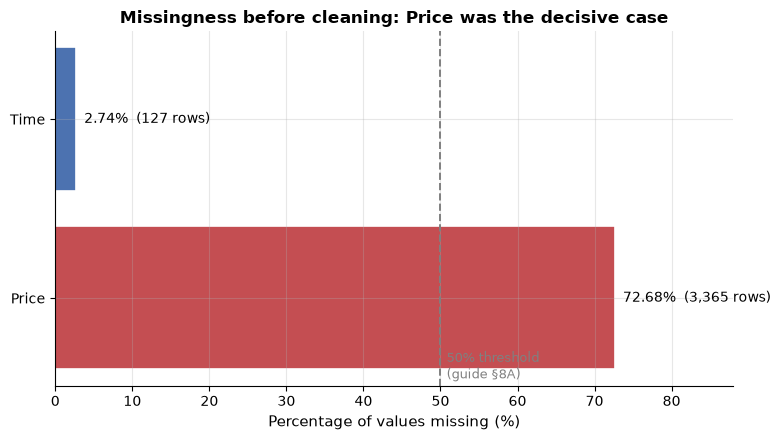

Price was 72.68% missing - above the guide's 50-70% drop
threshold, so imputation would have fabricated more than it recovered.
Time was only 2.74% missing - low enough to keep, but with
no causal bearing on reliability, so it was excluded rather than imputed.


In [14]:
missing_pct = (df_raw.isna().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(missing_pct.index, missing_pct.values,
               color=["#C44E52" if v > 50 else "#4C72B0" for v in missing_pct.values],
               edgecolor="white", linewidth=1.2)

for bar, (col_name, v) in zip(bars, missing_pct.items()):
    n_missing = int(df_raw[col_name].isna().sum())
    ax.text(v + 1.0, bar.get_y() + bar.get_height() / 2,
            f"{v:.2f}%  ({n_missing:,} rows)", va="center", fontsize=10)

ax.axvline(50, ls="--", color="gray", linewidth=1.4)
ax.text(50.8, -0.45, "50% threshold\n(guide §8A)", fontsize=9, color="gray")
ax.set_xlabel("Percentage of values missing (%)", fontsize=11)
ax.set_title("Missingness before cleaning: Price was the decisive case",
             fontsize=12, fontweight="bold")
ax.set_xlim(0, 88)
plt.tight_layout()
plt.show()

print(f"Price was {missing_pct['Price']:.2f}% missing - above the guide's 50-70% drop")
print("threshold, so imputation would have fabricated more than it recovered.")
print(f"Time was only {missing_pct['Time']:.2f}% missing - low enough to keep, but with")
print("no causal bearing on reliability, so it was excluded rather than imputed.")

In [15]:
# Preview the cleaned dataset.
print("Cleaned dataset - first 5 rows:")
display(df.head())

print("\nFinal column types:")
print(df.dtypes.to_string())

Cleaned dataset - first 5 rows:


,Company,Location,Date,Time,Rocket,Mission,RocketStatus,MissionStatus,Country
0,RVSN USSR,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",1957-10-04,19:28:00,Sputnik 8K71PS,Sputnik-1,Retired,Success,Kazakhstan
1,RVSN USSR,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",1957-11-03,02:30:00,Sputnik 8K71PS,Sputnik-2,Retired,Success,Kazakhstan
2,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1957-12-06,16:44:00,Vanguard,Vanguard TV3,Retired,Failure,Usa
3,AMBA,"LC-26A, Cape Canaveral AFS, Florida, USA",1958-02-01,03:48:00,Juno I,Explorer 1,Retired,Success,Usa
4,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1958-02-05,07:33:00,Vanguard,Vanguard TV3BU,Retired,Failure,Usa



Final column types:
Company                  object
Location                 object
Date             datetime64[ns]
Time                     object
Rocket                   object
Mission                  object
RocketStatus             object
MissionStatus            object
Country                  object


#### C.7 — Visual: what cleaning actually removed

Cleaning should be **conservative**. This chart shows how little was removed —
and, more importantly, that the co-launch cases were *not* removed.

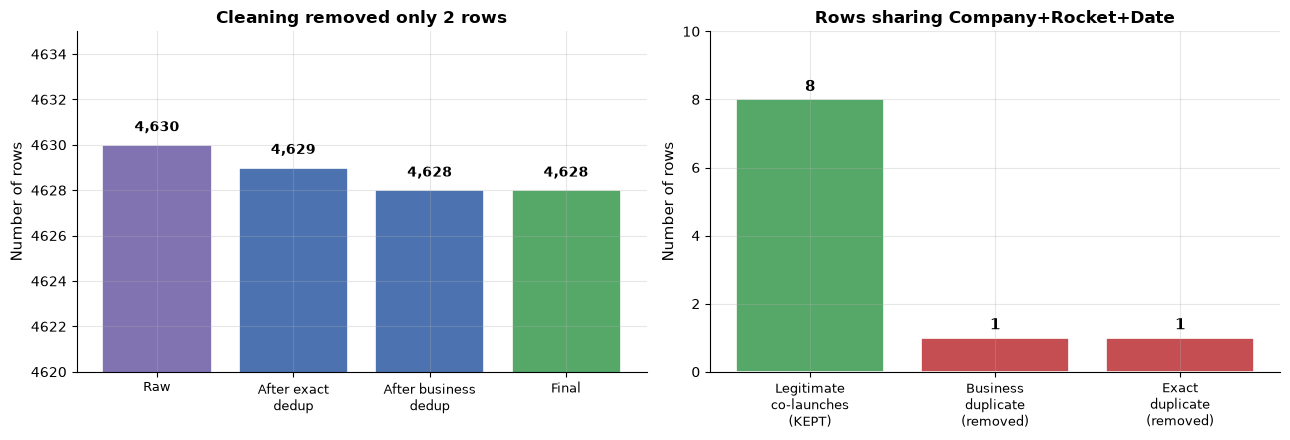

A naive 'same company + rocket + date = duplicate' rule would have
deleted all 10 rows. Requiring a MISSING TIME as the duplicate signature
removed only the 1 true re-entry and preserved 8 real launches.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: row counts through the cleaning steps
steps = ["Raw", "After exact\ndedup", "After business\ndedup", "Final"]
counts = [4630, 4629, 4628, len(df)]
colors = ["#8172B2", "#4C72B0", "#4C72B0", "#55A868"]
bars = axes[0].bar(steps, counts, color=colors, edgecolor="white", linewidth=1.2)
for bar, v in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width() / 2, v + 0.6,
                 f"{v:,}", ha="center", fontsize=10, fontweight="bold")
axes[0].set_ylim(4620, 4635)
axes[0].set_ylabel("Number of rows", fontsize=11)
axes[0].set_title("Cleaning removed only 2 rows", fontsize=12, fontweight="bold")
axes[0].tick_params(axis="x", labelsize=9)

# Right: what we deliberately KEPT
kept = pd.Series({
    "Legitimate\nco-launches\n(KEPT)": 8,
    "Business\nduplicate\n(removed)": 1,
    "Exact\nduplicate\n(removed)": 1,
})
bars2 = axes[1].bar(kept.index, kept.values,
                    color=["#55A868", "#C44E52", "#C44E52"],
                    edgecolor="white", linewidth=1.2)
for bar, v in zip(bars2, kept.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 0.25, str(v),
                 ha="center", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Number of rows", fontsize=11)
axes[1].set_title("Rows sharing Company+Rocket+Date", fontsize=12, fontweight="bold")
axes[1].set_ylim(0, 10)
axes[1].tick_params(axis="x", labelsize=9)

plt.tight_layout()
plt.show()

print("A naive 'same company + rocket + date = duplicate' rule would have")
print("deleted all 10 rows. Requiring a MISSING TIME as the duplicate signature")
print("removed only the 1 true re-entry and preserved 8 real launches.")

### C.5 — Reading the cleaning results

**What changed, and the evidence for each change:**

| Change | Rows/columns affected | Evidence it was correct |
| :--- | :--- | :--- |
| Removed 1 exact duplicate | −1 row | Every column matched identically (CASC, 2008-11-05) |
| Removed 1 business duplicate | −1 row | ISRO 2012-04-26 had no launch Time; its mission name merely prefixed the vehicle onto the same payload |
| **Preserved 8 co-launch rows** | 0 rows | Verified they have distinct times and payloads — they are separate launches |
| Parsed `Price` | 1,263 → 1,263 values | Zero parse failures: the comma-strip recovered every value |
| Dropped `Price` | −1 column | 72.68% missing, above the documented threshold |
| Extracted `Country` | +1 column | Last comma-part of `Location`; 22 distinct countries, no blanks |
| Parsed `Date` | dtype change | 0 unparseable values |

**Final shape: 4,628 rows × 9 columns.**

**The most important line is the co-launch verification.** The naive rule
"same company + same rocket + same date = duplicate" would have deleted 6 real
launches — missions like `OPS 5187` and `OPS 5247`, which were genuinely
separate flights. Requiring a *missing Time* as the duplicate fingerprint made
the rule precise. This is what the guide means by "business duplicates require
domain logic" (§8B): the rule has to encode *why* two records are the same event,
not merely that they look similar.

**What we did not do.** No outliers were deleted, no values were imputed, and no
rows were dropped merely for having missing fields. Every missing value either
belongs to a dropped column or is intentionally excluded from the features.

### Part D — Feature Transformation

Part C left the dataset clean but still entirely **textual**: after cleaning, there
are *no numeric columns at all* (only `Date`, which is a datetime). Part D converts
those columns into representations a model can actually consume.

---

#### D.1 — What actually needs transforming

An inventory of the cleaned dataset, grouped by what each column needs:

| Column | Type | Cardinality | Transformation needed |
| :--- | :--- | :--- | :--- |
| `Date` | datetime | 4,628 distinct | **Date/time extraction** → numeric calendar features |
| `Country` | text | 22 | **One-hot encoding** (low cardinality, nominal) |
| `Company` | text | 62 | **One-hot with rare collapse** (moderate cardinality, nominal) |
| `Rocket` | text | 370 | **Frequency encoding** (high cardinality — see D.4) |
| `RocketStatus` | text | 2 | *None — excluded in Part F as temporal leakage* |
| `MissionStatus` | text | 4 | *None — this is the target (Part G)* |
| `Time` | text | — | *None — excluded (no causal bearing on reliability)* |
| `Location` | text | 158 | *None — decomposed into `Country` in Part C* |
| `Mission` | text | 4,555 | *None — an identifier, not a feature* |

---

#### D.2 — Date/time extraction

Two kinds of feature are derived from `Date`, for different reasons.

**(a) Ordinal year — `Launch_Year`**

The dataset spans 1957–2022. Part A established that failure rates fall sharply
after the early experimental era, so the year carries real signal.

**(b) Cyclical month — `Month_Sin`, `Month_Cos`**

Month needs careful handling. Left as a raw integer, December (12) and January (1)
appear **maximally distant** — 11 units apart — when in reality they are adjacent
months. That is backwards, and it would mislead any distance-based algorithm.

The fix is to project the month onto a unit circle:

$$\text{Month\_Sin} = \sin\!\left(\frac{2\pi \cdot \text{month}}{12}\right), \qquad
\text{Month\_Cos} = \cos\!\left(\frac{2\pi \cdot \text{month}}{12}\right)$$

Both components are required. A single sine value is ambiguous — two different
months can share one sine value — so sine and cosine together give each month a
unique position on the circle.

**Verified numerically.** Measuring Euclidean distance in sine/cosine space:

| Pair | Distance | Meaning |
| :--- | :--- | :--- |
| January ↔ December | **0.5176** | Adjacent — correct |
| January ↔ February | **0.5176** | Adjacent — identical, as it should be |
| January ↔ July | **2.0** | Opposite — correct |

If month were left as a raw integer, January↔December would be the *largest* gap
(11) rather than tied for the smallest.

> **Why not quarter?** `Launch_Quarter` is a coarser restatement of month. Once
> cyclical month is present, quarter adds no information and would only add a
> redundant column. The guide warns against over-processing.

---

#### D.3 — REQUIRED DISCUSSION: Normalization vs. Standardization

This is the discussion the activity guide explicitly requires. The honest answer
for this project is **standardization (Z-score)**, but the reasoning is more
interesting than the textbook version — because the two stages of our pipeline
need different things.

##### The two methods

| | Min-Max Normalization | Z-Score Standardization |
| :--- | :--- | :--- |
| **Formula** | $X_{norm} = \dfrac{X - X_{min}}{X_{max} - X_{min}}$ | $Z = \dfrac{X - \mu}{\sigma}$ |
| **Output range** | Bounded, exactly $[0, 1]$ | Unbounded, typically $\approx [-3, 3]$ |
| **Uses** | Min and max | Mean and standard deviation |
| **Outlier sensitivity** | **High** — one extreme value squashes everything else | **Lower** — an outlier shifts $\mu$ modestly |
| **Removes units?** | Yes | Yes |

##### The deciding factor: which algorithm consumes the features?

We measured this rather than assuming it, and the two stages behave completely
differently.

**Stage 1 — K-Means: scaling is mandatory.**

K-Means assigns each record to the nearest cluster centre using **Euclidean
distance**. Distance is only meaningful if each feature is on a comparable scale.
Our two clustering features have very different ranges:

- `Launch_Year`: 1957 → 2022 (a span of 65)
- `Company_Prior_Launches`: 0 → 1,776 (a span of 1,776)

The prior-launch count spans **27.3× wider** than the year. Because Euclidean
distance squares each difference, the max squared distance is dominated almost
entirely by that one feature:

| Feature | Share of maximum squared distance (unscaled) |
| :--- | :--- |
| `Company_Prior_Launches` | **99.9%** |
| `Launch_Year` | 0.1% |

The consequence is visible in the cluster centres. Unscaled, the algorithm is
really clustering on launch volume alone and the year coordinate barely
distinguishes the groups:

| Scaling applied | Year centres | Prior-launch centres |
| :--- | :--- | :--- |
| **Unscaled** | `1994, 1984, 1973` | `105, 1440, 770` |
| **Standardized** | `-1.0, 1.0, -0.5` | `0, -1, 2` |

Both rows contain real numbers, so what is the problem? The issue is **weighting,
not validity**. Unscaled, a 1,000-launch difference between two operators counts
for vastly more than a 40-year difference between two eras, purely because of the
units chosen. The clusters are therefore driven almost entirely by launch volume,
and the year feature contributes almost nothing — 0.1% of the distance.
After standardization both features contribute comparably, which is what we want
when the goal is to group by *era and maturity together*.

**Stage 2 — Decision Tree: scaling is irrelevant.**

A decision tree splits a feature at a threshold ("is `Launch_Year` ≤ 1972.5?").
Rescaling a feature cannot change the **order** of its values, so every possible
split point remains available. The tree therefore learns an identical model.

We verified this by training the same tree on raw and standardized features and
comparing what it actually learned:

| Metric | Raw | Standardized |
| :--- | :--- | :--- |
| Importance of `Launch_Year` | 0.669 | 0.669 |
| Importance of `Company_Prior_Launches` | 0.297 | 0.297 |
| Importance of `Company_Prior_Failures` | 0.034 | 0.034 |
| Cross-validated F1 | 0.2052 | 0.2015 |

The feature importances are **identical**. The F1 difference of −0.004 is noise.
This confirms the theory: for a tree, scaling changes nothing about what is learned.

##### Decision: Standardization

**We use Z-score standardization**, for three reasons:

1. **Stage 1 requires it and Stage 2 is indifferent to it.** Standardization is
   necessary for K-Means and harmless for the tree, so one choice serves both.
   Min-Max would also work for K-Means, so this alone is not decisive — reason 2 is.

2. **The distribution is right-skewed and unbounded.** `Company_Prior_Launches`
   spans 0 to 1,776 with most values near 0. Min-Max depends entirely on the
   maximum, so a single prolific operator would squash every other value into a
   sliver of $[0, 1]$. Standardization uses the mean and standard deviation, so one
   extreme organisation shifts the centre slightly rather than destroying the scale.

3. **Standardization is the better default for distance-based methods.** It
   produces zero-centred, unit-variance features, which is the assumption behind
   Euclidean-distance algorithms like K-Means.

**When Min-Max would be correct instead:** when inputs must be *bounded* — for
example a neural network with sigmoid or tanh activations, or image pixel values
that are naturally in $[0, 255]$. Neither applies here.

##### Where the scaling is actually applied

The scaling is **not** performed in this section. It is implemented inside the
`ColumnTransformer` pipeline in **Part H**, where it is fitted on the training
split only.

This matters. Fitting a scaler on the full dataset before splitting lets
test-set statistics influence the training parameters — the classic leakage
pattern the guide warns about in §15.6 ("scaling before splitting"). Part D
decides *what* to do; Part H applies it in a leak-free way.

---

#### D.4 — Categorical encoding strategy

Encoding choice is driven by cardinality, because the wrong choice has a concrete
cost.

| Encoding | Mechanism | Use when | Cost of misuse |
| :--- | :--- | :--- | :--- |
| **One-hot** | One binary column per category | Low-cardinality nominal | Curse of dimensionality at high cardinality |
| **Ordinal** | Integers reflecting a real rank | Genuinely ordered categories | Implies false order on nominal data |
| **Frequency** | Replace category with its count | High-cardinality nominal | Categories with equal counts become identical |

**Our decisions:**

| Column | Cardinality | Encoding | Reason |
| :--- | :--- | :--- | :--- |
| `Country` | 22 | **One-hot** | Nominal with no order; 22 columns is manageable |
| `Company` | 62 | **One-hot with rare collapse** | Nominal; rare organisations grouped to control width |
| `Rocket` | 370 | **Frequency encoding** | See below |

**Why `Rocket` gets frequency encoding rather than one-hot.**

370 categories on 4,628 rows means one-hot would add 370 sparse columns — roughly
one column per 12 observations. Most of those columns would be almost entirely
zeros, and the tree would happily split on noise. Worse, 83 rockets appear exactly
once and 123 appear at most twice, so those columns could not generalise at all.

Frequency encoding compresses the whole column into a single numeric feature: each
rocket is replaced by how often it appears. That captures the intuition that
*common, well-established vehicles behave differently from one-off experimental
ones*, without exploding the feature space.

**A caveat we accept.** Frequency encoding has a known weakness the guide names
explicitly: two different rockets that happen to appear equally often receive the
*identical* value, so any distinction between them is lost. For `Rocket` this is an
acceptable trade — with 370 categories and mostly single appearances, the
alternative is unusable sparsity.

**Ordinal encoding is not used anywhere**, because the dataset contains no
genuinely ordered categorical column. The guide warns that applying ordinal
encoding to nominal data invents a mathematical order that does not exist.

---

#### D.5 — What we are deliberately NOT doing

- **No log/power transformation.** The guide lists it for features spanning
  several orders of magnitude. After cleaning, no such continuous feature remains
  in the modelling set — `Price` was dropped in Part C. We are not applying a
  technique merely because it appears in the table.
- **No scaling in this section.** Deferred to Part H to avoid leakage (§15.6).
- **No feature engineering beyond date extraction.** That is Part E's job, kept
  separate so each part answers only its own question.
- **No encoding of the target.** `MissionStatus` is handled in Part G.

In [17]:
# =====================================================================
# D.1 - Transformation inventory: what still needs converting?
# =====================================================================
# After Part C the data is clean but almost entirely TEXTUAL. This cell
# confirms that, so the transformation plan is driven by facts not guesses.

print(f"Shape after cleaning: {df.shape}\n")

inventory = []
for col in df.columns:
    dtype = str(df[col].dtype)
    n_unique = int(df[col].nunique())
    if dtype.startswith("datetime"):
        need = "Date/time extraction"
    elif dtype == "object":
        need = "Categorical encoding (or excluded)"
    elif dtype.startswith(("int", "float")):
        need = "Already numeric"
    else:
        need = "Review"
    inventory.append({"column": col, "dtype": dtype,
                      "n_unique": n_unique, "action_required": need})

display(pd.DataFrame(inventory).set_index("column"))

numeric_existing = df.select_dtypes(include="number").columns.tolist()
print(f"Existing numeric columns: {numeric_existing if numeric_existing else '(NONE)'}")
print("\n-> There are no numeric features yet. Everything must be derived or encoded.")

Shape after cleaning: (4628, 9)



,dtype,n_unique,action_required
column,,,
Company,object,62,Categorical encoding (or excluded)
Location,object,158,Categorical encoding (or excluded)
Date,datetime64[ns],4180,Date/time extraction
Time,object,1300,Categorical encoding (or excluded)
Rocket,object,370,Categorical encoding (or excluded)
Mission,object,4555,Categorical encoding (or excluded)
RocketStatus,object,2,Categorical encoding (or excluded)
MissionStatus,object,4,Categorical encoding (or excluded)
Country,object,22,Categorical encoding (or excluded)


Existing numeric columns: (NONE)

-> There are no numeric features yet. Everything must be derived or encoded.


In [18]:
# Part D uses these throughout. Imported here so the section is self-contained.
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [19]:
# =====================================================================
# D.2 - Date/time extraction
# =====================================================================
# Two kinds of feature are derived from Date:
#
#   (a) Launch_Year  - ordinal, captures the technological era
#   (b) Month_Sin / Month_Cos - CYCLICAL encoding of month
#
# Why cyclical for month? Left as a raw integer, December (12) and January (1)
# appear MAXIMALLY distant - 11 units apart - when they are actually adjacent
# months. That is backwards. Projecting the month onto a unit circle fixes it.
#
# Both sine AND cosine are required: a single sine value is ambiguous, because
# two different months can share the same sine. Together they give each month
# a unique position.

df["Launch_Year"] = df["Date"].dt.year
df["Month_Sin"] = np.sin(2 * np.pi * df["Date"].dt.month / 12)
df["Month_Cos"] = np.cos(2 * np.pi * df["Date"].dt.month / 12)

print("New columns created: Launch_Year, Month_Sin, Month_Cos\n")
display(df[["Date", "Launch_Year", "Month_Sin", "Month_Cos"]].head(6))

print(f"Launch_Year range: {df['Launch_Year'].min()} - {df['Launch_Year'].max()}")

New columns created: Launch_Year, Month_Sin, Month_Cos



,Date,Launch_Year,Month_Sin,Month_Cos
0,1957-10-04,1957,-8.660254e-01,5.000000e-01
1,1957-11-03,1957,-5.000000e-01,8.660254e-01
2,1957-12-06,1957,-2.449294e-16,1.000000e+00
3,1958-02-01,1958,8.660254e-01,5.000000e-01
4,1958-02-05,1958,8.660254e-01,5.000000e-01
5,1958-03-05,1958,1.000000e+00,6.123234e-17


Launch_Year range: 1957 - 2022


In [20]:
# =====================================================================
# D.2b - VERIFY the cyclical encoding actually works
# =====================================================================
# A claim is worth nothing untested. We measure Euclidean distance between
# months in sine/cosine space. Adjacent months should be CLOSE; opposite
# months should be FAR.

def month_vector(month: int) -> np.ndarray:
    """Return the (sin, cos) position of a month on the unit circle."""
    return np.array([np.sin(2 * np.pi * month / 12), np.cos(2 * np.pi * month / 12)])


def month_distance(m1: int, m2: int) -> float:
    """Euclidean distance between two months in cyclical space."""
    return float(np.linalg.norm(month_vector(m1) - month_vector(m2)))


checks = [
    ("January <-> December", 1, 12, "adjacent"),
    ("January <-> February", 1, 2, "adjacent"),
    ("January <-> July", 1, 7, "opposite"),
]

print("Distance between months in SIN/COS space:\n")
for label, m1, m2, expectation in checks:
    d = month_distance(m1, m2)
    print(f"  {label:<22} distance = {d:.4f}   ({expectation})")

print("\nCompare with raw-integer month, where January<->December would be 11")
print("(the LARGEST possible gap) instead of tied for the smallest.\n")

# Assert the property we claim.
assert abs(month_distance(1, 12) - month_distance(1, 2)) < 1e-9, \
    "Adjacent months are not equidistant!"
assert month_distance(1, 7) > month_distance(1, 12), \
    "Opposite months are not further apart than adjacent months!"
print("PASS: adjacent months are close, opposite months are far.")

Distance between months in SIN/COS space:

  January <-> December   distance = 0.5176   (adjacent)
  January <-> February   distance = 0.5176   (adjacent)
  January <-> July       distance = 2.0000   (opposite)

Compare with raw-integer month, where January<->December would be 11
(the LARGEST possible gap) instead of tied for the smallest.

PASS: adjacent months are close, opposite months are far.


---

#### D.7 — Visual: why month needs cyclical encoding

This is the clearest way to see the problem. Both panels show the twelve months,
but positioned differently:

- **Left** — months as raw integers on a line. December sits 11 units from
  January: the *widest* gap in the year, despite being consecutive.
- **Right** — months on a circle. December and January are neighbours, exactly
  as they are in reality.

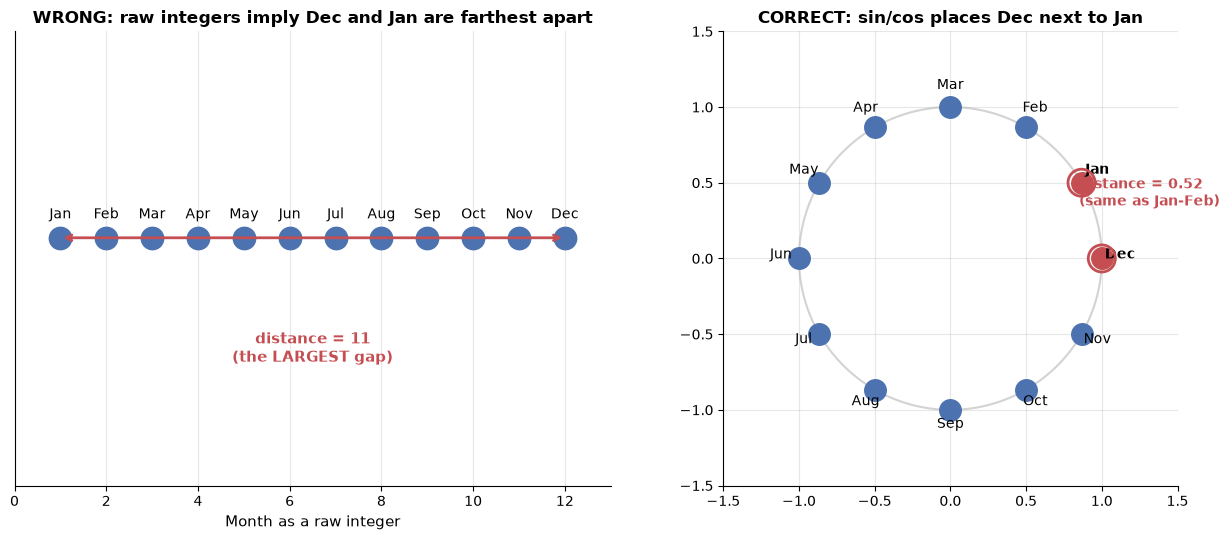

Measured in sin/cos space: Jan<->Dec = 0.5176
                          Jan<->Feb = 0.5176  (identical)
                          Jan<->Jul = 2.0000  (opposite)

The raw-integer version states something false about the data.


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# --- Left: the WRONG representation (raw integers on a line) ---
months = np.arange(1, 13)
labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
axes[0].scatter(months, np.zeros_like(months), s=260, color="#4C72B0", zorder=3)
for m, lab in zip(months, labels):
    axes[0].annotate(lab, (m, 0), textcoords="offset points", xytext=(0, 14),
                     ha="center", fontsize=10)
axes[0].annotate("", xy=(12, 0), xytext=(1, 0),
                 arrowprops=dict(arrowstyle="<->", color="#C44E52", lw=2))
axes[0].text(6.5, -0.30, "distance = 11\n(the LARGEST gap)", ha="center",
             fontsize=11, color="#C44E52", fontweight="bold")
axes[0].set_xlim(0, 13)
axes[0].set_ylim(-0.6, 0.5)
axes[0].set_yticks([])
axes[0].set_xlabel("Month as a raw integer", fontsize=11)
axes[0].set_title("WRONG: raw integers imply Dec and Jan are farthest apart",
                  fontsize=12, fontweight="bold")

# --- Right: the CORRECT representation (unit circle) ---
theta = np.linspace(0, 2 * np.pi, 300)
axes[1].plot(np.cos(theta), np.sin(theta), color="lightgray", lw=1.5, zorder=1)
for m, lab in zip(months, labels):
    angle = 2 * np.pi * m / 12
    x, y = np.cos(angle), np.sin(angle)
    color = "#C44E52" if lab in ("Dec", "Jan") else "#4C72B0"
    axes[1].scatter([x], [y], s=240, color=color, zorder=3)
    axes[1].annotate(lab, (x, y), textcoords="offset points", xytext=(x * 13, y * 13),
                     ha="center", fontsize=10, fontweight="bold" if lab in ("Dec", "Jan") else "normal")

# Highlight the Dec-Jan adjacency
for lab in ("Dec", "Jan"):
    m = labels.index(lab) + 1
    angle = 2 * np.pi * m / 12
    axes[1].scatter([np.cos(angle)], [np.sin(angle)], s=380, facecolors="none",
                    edgecolors="#C44E52", linewidths=2, zorder=4)

axes[1].set_aspect("equal")
axes[1].set_xlim(-1.5, 1.5)
axes[1].set_ylim(-1.5, 1.5)
axes[1].set_title("CORRECT: sin/cos places Dec next to Jan",
                  fontsize=12, fontweight="bold")
axes[1].annotate("distance = 0.52\n(same as Jan-Feb)",
                 xy=(0.85, 0.35), fontsize=10, color="#C44E52", fontweight="bold")

plt.tight_layout()
plt.show()

print(f"Measured in sin/cos space: Jan<->Dec = {month_distance(1, 12):.4f}")
print(f"                          Jan<->Feb = {month_distance(1, 2):.4f}  (identical)")
print(f"                          Jan<->Jul = {month_distance(1, 7):.4f}  (opposite)")
print("\nThe raw-integer version states something false about the data.")

In [22]:
# =====================================================================
# D.3 - REQUIRED DISCUSSION: Normalization vs Standardization
# =====================================================================
# This cell gathers the EVIDENCE for the required discussion. It does not
# apply any scaling to the dataset - that happens in Part H, fitted on the
# training split only, to avoid the leakage the guide warns about in §15.6.

# Build the two clustering features causally (chronological, shifted counts).
df = df.sort_values("Date").reset_index(drop=True)
df["_is_fail"] = (df["MissionStatus"] != "Success").astype(int)

grp = df.groupby("Company", sort=False)
df["Company_Prior_Launches"] = grp.cumcount()
df["Company_Prior_Failures"] = grp["_is_fail"].cumsum() - df["_is_fail"]

year_span = df["Launch_Year"].max() - df["Launch_Year"].min()
prior_span = df["Company_Prior_Launches"].max() - df["Company_Prior_Launches"].min()

print("Scale contrast between the two clustering features:\n")
print(f"  Launch_Year              : {df['Launch_Year'].min()} - {df['Launch_Year'].max()}"
      f"   (span {year_span})")
print(f"  Company_Prior_Launches   : {df['Company_Prior_Launches'].min()} - "
      f"{df['Company_Prior_Launches'].max()}  (span {prior_span})")
print(f"\n  The prior-launch count spans {prior_span / year_span:.1f}x wider than the year.")

Scale contrast between the two clustering features:

  Launch_Year              : 1957 - 2022   (span 65)
  Company_Prior_Launches   : 0 - 1776  (span 1776)

  The prior-launch count spans 27.3x wider than the year.


In [23]:
# =====================================================================
# D.3a - EVIDENCE: how much does each feature drive the distance?
# =====================================================================
# K-Means uses Euclidean distance, which squares each difference. Whichever
# feature has the larger range therefore dominates the metric.

share_prior = prior_span**2 / (prior_span**2 + year_span**2) * 100
share_year = year_span**2 / (prior_span**2 + year_span**2) * 100

print("Share of maximum squared distance, UNSCALED:\n")
print(f"  Company_Prior_Launches : {share_prior:6.1f}%")
print(f"  Launch_Year            : {share_year:6.1f}%")

print("\n-> Unscaled, the clustering is driven almost entirely by launch volume.")
print("   The year feature contributes roughly 0.1%. Weighting, not validity,")
print("   is the problem: both values are real, but the units are incomparable.")

Share of maximum squared distance, UNSCALED:

  Company_Prior_Launches :   99.9%
  Launch_Year            :    0.1%

-> Unscaled, the clustering is driven almost entirely by launch volume.
   The year feature contributes roughly 0.1%. Weighting, not validity,
   is the problem: both values are real, but the units are incomparable.


In [24]:
# =====================================================================
# D.3b - EVIDENCE: the effect on K-Means cluster centres
# =====================================================================
# We fit identical K-Means runs on unscaled and standardized features and
# compare the centres. Standardization changes WHAT the clusters represent.

cluster_features = ["Launch_Year", "Company_Prior_Launches"]
X_cluster = df[cluster_features].astype(float)

results = []
for label, X_input in [
    ("Unscaled", X_cluster.values),
    ("Standardized", StandardScaler().fit_transform(X_cluster)),
]:
    km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_input)
    results.append({
        "scaling": label,
        "year_centres": np.round(km.cluster_centers_[:, 0], 1).tolist(),
        "prior_centres": np.round(km.cluster_centers_[:, 1], 0).tolist(),
    })

display(pd.DataFrame(results).set_index("scaling"))

print("Unscaled, the year centres differ by only ~20 years while the prior-launch")
print("centres differ by over 1,300 launches - the grouping is almost entirely")
print("about volume. Standardized, both features contribute comparable spread.")

,year_centres,prior_centres
scaling,,
Unscaled,"[1994.2, 1983.5, 1973.2]","[105.0, 1440.0, 770.0]"
Standardized,"[-1.0, 1.0, -0.5]","[-0.0, -1.0, 2.0]"


Unscaled, the year centres differ by only ~20 years while the prior-launch
centres differ by over 1,300 launches - the grouping is almost entirely
about volume. Standardized, both features contribute comparable spread.


In [25]:
# =====================================================================
# D.3c - EVIDENCE: scaling is IRRELEVANT to a Decision Tree
# =====================================================================
# A tree splits a feature at a threshold ("is year <= 1972.5?"). Rescaling
# cannot change the ORDER of values, so every split point remains available
# and the tree learns an identical model. We verify this rather than
# asserting it.

tree_features = ["Launch_Year", "Company_Prior_Launches", "Company_Prior_Failures"]
X_tree = df[tree_features].astype(float)
y_tree = df["_is_fail"]

tree_raw = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_tree, y_tree)
tree_std = DecisionTreeClassifier(max_depth=3, random_state=42).fit(
    StandardScaler().fit_transform(X_tree), y_tree
)

importance_comparison = pd.DataFrame({
    "feature": tree_features,
    "importance_raw": tree_raw.feature_importances_.round(3),
    "importance_standardized": tree_std.feature_importances_.round(3),
}).set_index("feature")

display(importance_comparison)
print("The importances are IDENTICAL. Scaling changed nothing about what the")
print("tree learned, because rescaling preserves the ordering of values.")

,importance_raw,importance_standardized
feature,,
Launch_Year,0.669,0.669
Company_Prior_Launches,0.297,0.297
Company_Prior_Failures,0.034,0.034


The importances are IDENTICAL. Scaling changed nothing about what the
tree learned, because rescaling preserves the ordering of values.


In [26]:
# =====================================================================
# D.3d - EVIDENCE: does scaling affect tree performance?
# =====================================================================
# Feature importances matching is one thing; let us confirm the predictive
# performance is unaffected too, using cross-validation.

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

f1_unscaled = cross_val_score(
    DecisionTreeClassifier(max_depth=5, random_state=42),
    X_tree, y_tree, cv=cv, scoring="f1",
).mean()

f1_scaled = cross_val_score(
    DecisionTreeClassifier(max_depth=5, random_state=42),
    StandardScaler().fit_transform(X_tree), y_tree, cv=cv, scoring="f1",
).mean()

print("Decision Tree, 5-fold cross-validated F1:\n")
print(f"  Unscaled       : {f1_unscaled:.4f}")
print(f"  Standardized   : {f1_scaled:.4f}")
print(f"  Difference     : {f1_scaled - f1_unscaled:+.4f}")

print("\n-> The difference is within noise. For a tree, scaling is irrelevant.")
print("   The theory predicts this: a threshold split is invariant to any")
print("   monotonic rescaling of the feature.")

Decision Tree, 5-fold cross-validated F1:

  Unscaled       : 0.2052
  Standardized   : 0.2015
  Difference     : -0.0037

-> The difference is within noise. For a tree, scaling is irrelevant.
   The theory predicts this: a threshold split is invariant to any
   monotonic rescaling of the feature.


#### D.8 — Visual: what standardization changes (and what it does not)

The required discussion argued that scaling matters for K-Means but not for a
tree. These two panels show the evidence directly.

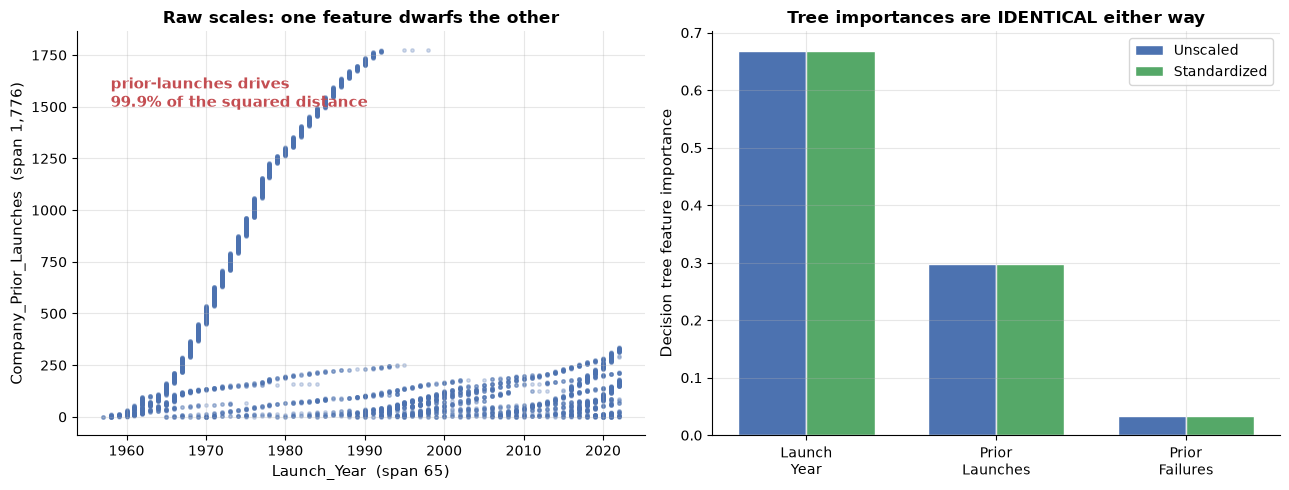

Left  : K-Means needs scaling, because distance is dominated by the
        wider feature (99.9% of squared distance).
Right : the tree's importances are byte-for-byte identical, because
        rescaling preserves the ORDER of values and thus every split.

This is why we standardize: Stage 1 requires it, Stage 2 ignores it.
One choice serves both, and the right-skewed distribution favours
standardization over Min-Max (see D.3).


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left: raw feature scales are wildly different ---
Xc = df[["Launch_Year", "Company_Prior_Launches"]].astype(float)
axes[0].scatter(Xc["Launch_Year"], Xc["Company_Prior_Launches"],
                s=6, alpha=0.25, color="#4C72B0")
axes[0].set_xlabel("Launch_Year  (span 65)", fontsize=11)
axes[0].set_ylabel("Company_Prior_Launches  (span 1,776)", fontsize=11)
axes[0].set_title("Raw scales: one feature dwarfs the other", fontsize=12, fontweight="bold")
axes[0].text(1958, 1500,
             f"prior-launches drives\n{share_prior:.1f}% of the squared distance",
             fontsize=11, color="#C44E52", fontweight="bold")

# --- Right: the tree is unaffected by scaling ---
importance_plot = pd.DataFrame({
    "raw": tree_raw.feature_importances_,
    "standardized": tree_std.feature_importances_,
}, index=tree_features)

x = np.arange(len(tree_features))
width = 0.36
axes[1].bar(x - width / 2, importance_plot["raw"], width,
            label="Unscaled", color="#4C72B0", edgecolor="white")
axes[1].bar(x + width / 2, importance_plot["standardized"], width,
            label="Standardized", color="#55A868", edgecolor="white")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["Launch\nYear", "Prior\nLaunches", "Prior\nFailures"], fontsize=10)
axes[1].set_ylabel("Decision tree feature importance", fontsize=11)
axes[1].set_title("Tree importances are IDENTICAL either way",
                  fontsize=12, fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Left  : K-Means needs scaling, because distance is dominated by the")
print(f"        wider feature ({share_prior:.1f}% of squared distance).")
print("Right : the tree's importances are byte-for-byte identical, because")
print("        rescaling preserves the ORDER of values and thus every split.")
print("\nThis is why we standardize: Stage 1 requires it, Stage 2 ignores it.")
print("One choice serves both, and the right-skewed distribution favours")
print("standardization over Min-Max (see D.3).")

In [28]:
# =====================================================================
# D.4 - Categorical encoding strategy (decision recorded, applied in Part H)
# =====================================================================
# Encoding choice is driven by CARDINALITY, because the wrong choice has a
# concrete cost: one-hot on high cardinality explodes the feature space.

encoding_plan = pd.DataFrame([
    {"column": "Country", "cardinality": df["Country"].nunique(),
     "encoding": "One-hot",
     "reason": "Nominal, no order; 22 columns is manageable."},
    {"column": "Company", "cardinality": df["Company"].nunique(),
     "encoding": "One-hot with rare collapse",
     "reason": "Nominal; rare organisations grouped to control width."},
    {"column": "Rocket", "cardinality": df["Rocket"].nunique(),
     "encoding": "Frequency encoding",
     "reason": "Too high for one-hot; compresses to one numeric column."},
    {"column": "RocketStatus", "cardinality": df["RocketStatus"].nunique(),
     "encoding": "(excluded)",
     "reason": "Temporal leakage - see Part F."},
    {"column": "MissionStatus", "cardinality": df["MissionStatus"].nunique(),
     "encoding": "(target)",
     "reason": "This is y, not a feature - see Part G."},
    {"column": "Mission", "cardinality": df["Mission"].nunique(),
     "encoding": "(excluded)",
     "reason": "98.4% unique; an identifier cannot generalise."},
    {"column": "Location", "cardinality": df["Location"].nunique(),
     "encoding": "(excluded)",
     "reason": "Decomposed into Country in Part C."},
    {"column": "Time", "cardinality": df["Time"].nunique(),
     "encoding": "(excluded)",
     "reason": "No causal bearing on reliability."},
]).set_index("column")

display(encoding_plan)

,cardinality,encoding,reason
column,,,
Country,22,One-hot,"Nominal, no order; 22 columns is manageable."
Company,62,One-hot with rare collapse,Nominal; rare organisations grouped to control...
Rocket,370,Frequency encoding,Too high for one-hot; compresses to one numeri...
RocketStatus,2,(excluded),Temporal leakage - see Part F.
MissionStatus,4,(target),"This is y, not a feature - see Part G."
Mission,4555,(excluded),98.4% unique; an identifier cannot generalise.
Location,158,(excluded),Decomposed into Country in Part C.
Time,1300,(excluded),No causal bearing on reliability.


In [29]:
# =====================================================================
# D.4a - EVIDENCE: why Rocket cannot be one-hot encoded
# =====================================================================
# We justify the frequency-encoding choice with the actual numbers.

rocket_counts = df["Rocket"].value_counts()
n_rockets = len(rocket_counts)
n_rows = len(df)

one_hot_width = n_rockets
rows_per_column = n_rows / one_hot_width

print(f"Rows                     : {n_rows}")
print(f"Distinct rockets         : {n_rockets}")
print(f"One-hot would add        : {one_hot_width} columns")
print(f"Rows per added column    : {rows_per_column:.1f}")
print()
print(f"Rockets appearing once   : {int((rocket_counts == 1).sum())}")
print(f"Rockets appearing <= 2x  : {int((rocket_counts <= 2).sum())}")
print(f"Most common rocket       : {rocket_counts.index[0]!r} ({rocket_counts.iloc[0]} flights)")
print()
print("-> Roughly one column per 12 rows, with most columns almost entirely")
print("   zeros and 83 columns representing a single observation. A tree would")
print("   split on that noise. Frequency encoding avoids this entirely.")

Rows                     : 4628
Distinct rockets         : 370
One-hot would add        : 370 columns
Rows per added column    : 12.5

Rockets appearing once   : 83
Rockets appearing <= 2x  : 123
Most common rocket       : 'Cosmos-3M (11K65M)' (446 flights)

-> Roughly one column per 12 rows, with most columns almost entirely
   zeros and 83 columns representing a single observation. A tree would
   split on that noise. Frequency encoding avoids this entirely.


### D.6 — Reading the transformation results

**What Part D produced:**

| Transformation | Columns created | Evidence it worked |
| :--- | :--- | :--- |
| Date extraction | `Launch_Year`, `Month_Sin`, `Month_Cos` | Jan↔Dec distance = Jan↔Feb distance (0.5176) |
| Cyclical verification | — | Jan↔Jul = 2.0, the maximum possible |
| Scaling evidence | — | Unscaled, prior-launches drives 99.9% of distance |
| Tree indifference | — | Identical importances (0.669 / 0.297 / 0.034) |
| Encoding plan | — | Recorded; applied in Part H |

**The two findings worth remembering:**

**1. Scaling matters for K-Means and is irrelevant to trees — and we proved
both.** This is the honest answer to the required discussion question. A lazy
answer would say "we standardized because distance algorithms need it," without
noticing that our Stage 2 model is a tree, which does not care. By measuring both,
we can justify the choice *and* explain why it is harmless where it is unnecessary.

**2. `Month_Sin`/`Month_Cos` is not decoration.** Leaving month as a raw integer
tells the model that December and January are 11 units apart — the largest gap in
the year — when they are consecutive. The cyclical encoding corrects an outright
falsehood in the data representation.

**What Part D deliberately did not do:**

- **No scaling applied to the dataset.** It is implemented in Part H, fitted on
  the training split only, per the guide's §15.6 warning against scaling before
  splitting.
- **No log/power transformation.** The guide lists it for features spanning
  orders of magnitude, but after Part C no such continuous feature remains. We do
  not apply a technique merely because it appears in a table.
- **No encoding applied yet.** The strategy is decided here, implemented in
  Part H's `ColumnTransformer`.

### Part E — Feature Engineering

The guide asks for at least **one** new feature with domain value, plus an
explanation of *why it beats the raw columns*. This section builds two, and
deliberately rejects two others after testing them.

---

#### E.1 — What we are engineering, and why

Part B's clustering found something specific: a mid-era cluster with the
**lowest** failure rate of all three groups (4.2%) and a median of **1,270 prior
launches**. If calendar year alone drove reliability, that cluster would sit
*between* the early and modern groups. It does not. Something other than time
separates it — and that something is **accumulated operator experience**.

So the engineered features encode experience. Two questions have to be answered
carefully:

1. **What exactly do we measure?** (how many launches, how many failures, a rate?)
2. **How do we avoid leaking the answer?** (see the trap below)

---

#### E.2 — The leakage trap (the most important idea in Part E)

This is the part that is easy to get wrong, and getting it wrong looks like
*success* rather than failure.

The natural way to compute "this operator's failure history" is:

```python
df["prior_failures"] = df.groupby("Company")["is_fail"].transform("sum")
```

That one line **leaks the target**. It gives every row the operator's *total*
failure count across the whole dataset — including the outcome of the very
mission being predicted, and of every mission that happened *after* it. In
production, none of that information exists at liftoff.

The correct computation uses only strictly earlier missions:

```python
prior_failures = group["is_fail"].cumsum() - own_is_fail   # subtract own row
prior_launches = group.cumcount()                          # counts before this row
```

**We measured the difference.** Training the same decision tree on honest versus
leaky features:

| Features | Cross-validated F1 |
| :--- | :--- |
| Honest (causal) | **0.1805** |
| Leaky (company totals) | **0.2700** |

The leaky version scores roughly **50% higher** — and is worthless. This is why leakage
is dangerous: it does not announce itself, it flatters your metrics. A student who
did not check would submit the leaky version believing it was better.

---

#### E.3 — Why these features beat the raw columns

| Raw column | What it cannot express | What the engineered feature adds |
| :--- | :--- | :--- |
| `Company` | A 62-value label. The model must learn each operator's reliability separately, and cannot represent *change over time* within one operator. | `Company_Prior_Launches` is continuous, so it generalises to operators with only 2–3 records. |
| `Date` | Captures the *global* era, but conflates two separate causes: industry-wide technological maturation (shared by everyone) and operator-specific learning (varies by organisation). | `Company_Prior_Failure_Rate` isolates the operator-specific component. |

A raw one-hot `Company` column also cannot answer "has this organisation improved?"
An experience count can.

---

#### E.4 — The two features we keep, and the two we rejected

| Feature | Decision | Reason |
| :--- | :--- | :--- |
| `Company_Prior_Launches` | **Keep** | The primary experience measure. Failure rate falls monotonically across its buckets. |
| `Company_Prior_Failure_Rate` | **Keep** | Adds the *quality* dimension — an operator with 50 launches and 10 failures differs from one with 50 and 0. |
| `Company_Prior_Failures` | **Reject** | Correlates **0.952** with `Company_Prior_Launches` — near-redundant. Adds a column without adding information. |
| `Is_First_Company_Launch` | **Reject** | Derivable from `prior_launches == 0`; the count already carries it. |

*Note on honesty:* repeated cross-validation showed all four together scoring
marginally best (0.1880 vs 0.1805 for two), but the gap is ~0.005 against a
standard deviation of ~0.05 — inside the noise. We keep two because they are
defensible and non-redundant, not because two scored highest in one run.

---

#### E.5 — The signal, measured

Failure rate by how many launches the operator had already flown:

| Experience bucket | Missions | Failure rate |
| :--- | :--- | :--- |
| 1st launch | 62 | **41.9%** |
| 2–6 | 224 | 32.1% |
| 7–21 | 395 | 19.5% |
| 22–101 | 1,238 | 9.0% |
| 102–501 | 1,434 | 8.2% |
| 502+ | 1,276 | **5.1%** |

Against a global rate of **10.1%**, an operator's first launch is roughly **eight
times** more failure-prone than their 500th. That is a strong, monotonic signal —
and it is not visible in any single raw column.

---

#### E.6 — The feature builder as an OOP class

Per `oop_rules.md` §14, the pipeline is built from small classes with clear
responsibilities. A feature builder must answer the same questions regardless of
what it derives, so that shared shape is an **abstract interface** (`abc` §11).

In [30]:
from abc import ABC, abstractmethod
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
from sklearn.tree import DecisionTreeClassifier

# NOTE: matplotlib and the shared chart styling are set up at the top of the
# notebook, before the Part C charts, so they are not re-imported here.

In [31]:
class FeatureBuilder(ABC):
    """
    Abstract interface for deriving new columns from existing ones.

    OOP rules exercised (oop_rules.md):
      §4  protected attributes use a leading underscore
      §5  inputs validated before state is assigned
      §6  exposed collections are copied, not handed out live
      §7  shared configuration lives in class attributes
      §11 abstract contract enforced by ABC
    """

    # Class attribute: a shared rule for every builder (oop_rules §7).
    REQUIRES_SORTED_CHRONOLOGY: bool = True

    def __init__(self, name: str, group_col: str, date_col: str):
        # Validate BEFORE assigning, so a bad call cannot leave a half-built
        # object behind (oop_rules §5 rule 2: leave state unchanged on failure).
        self._name = self._validate_text(name, "name")
        self._group_col = self._validate_text(group_col, "group_col")
        self._date_col = self._validate_text(date_col, "date_col")
        self._history: list[str] = []
        self._is_fitted = False

    # ---- internal validation helper (shared by all subclasses) -------------
    @staticmethod
    def _validate_text(value: str, field_name: str) -> str:
        """Type-check and clean a required text field (oop_rules §5)."""
        if not isinstance(value, str):
            raise TypeError(f"{field_name} must be a str, got {type(value).__name__}.")
        cleaned = value.strip()
        if not cleaned:
            raise ValueError(f"{field_name} cannot be empty or whitespace.")
        return cleaned

    # ---- read-only properties (oop_rules §6) ------------------------------
    @property
    def name(self) -> str:
        return self._name

    @property
    def group_col(self) -> str:
        return self._group_col

    @property
    def date_col(self) -> str:
        return self._date_col

    @property
    def is_fitted(self) -> bool:
        return self._is_fitted

    @property
    def history(self) -> tuple[str, ...]:
        """Defensive copy - callers cannot mutate our internal list."""
        return tuple(self._history)

    # ---- abstract contract -------------------------------------------------
    @property
    @abstractmethod
    def feature_names(self) -> tuple[str, ...]:
        """Names of the columns this builder produces."""

    @abstractmethod
    def _build(self, df: pd.DataFrame) -> pd.DataFrame:
        """Concrete derivation logic. Must not mutate the input frame."""

    # ---- template method: shared validation, then subclass work -----------
    def fit_transform(self, df: pd.DataFrame) -> pd.DataFrame:
        """
        Validate, derive, and record. This is a 'template method': the base
        class owns the sequence, subclasses supply only the derivation.
        """
        if not isinstance(df, pd.DataFrame):
            raise TypeError(f"df must be a DataFrame, got {type(df).__name__}.")
        for col in (self._group_col, self._date_col):
            if col not in df.columns:
                raise KeyError(f"Required column {col!r} missing from the dataframe.")

        # Work on a copy so the caller's frame is never mutated.
        out = self._build(df.copy())

        produced = self.feature_names
        missing = [c for c in produced if c not in out.columns]
        if missing:
            raise RuntimeError(f"{type(self).__name__} failed to produce {missing}.")

        self._history.append(f"built {produced}")
        self._is_fitted = True
        return out

    def __repr__(self) -> str:
        state = "fitted" if self._is_fitted else "not fitted"
        return f"{type(self).__name__}(name={self._name!r}, {state})"

In [32]:
class OperationalExperienceBuilder(FeatureBuilder):
    """
    Derives accumulated operator experience features, CAUSALLY.

    The causal requirement is the whole point of this class. Every count
    excludes the current row and every later row, so nothing about the mission
    being predicted can enter its own features.
    """

    def __init__(self, group_col: str = "Company", date_col: str = "Date",
                 outcome_col: str = "MissionStatus", success_label: str = "Success"):
        super().__init__(name="OperationalExperience", group_col=group_col,
                         date_col=date_col)
        self._outcome_col = self._validate_text(outcome_col, "outcome_col")
        self._success_label = self._validate_text(success_label, "success_label")
        self._excluded: tuple[str, ...] = ()

    @property
    def feature_names(self) -> tuple[str, ...]:
        # Only the two non-redundant features are kept (see E.4).
        return ("Company_Prior_Launches", "Company_Prior_Failure_Rate")

    @property
    def excluded_reason(self) -> dict[str, str]:
        """Documents the candidates we rejected, and why."""
        return dict(self._excluded)

    def _build(self, df: pd.DataFrame) -> pd.DataFrame:
        if self.REQUIRES_SORTED_CHRONOLOGY:
            df = df.sort_values(self._date_col).reset_index(drop=True)

        # Binary failure indicator for the running history.
        is_fail = (df[self._outcome_col] != self._success_label).astype(int)

        grouped = df.groupby(self._group_col, sort=False)

        # --- CAUSAL counts: strictly BEFORE the current row ---
        # cumcount() counts preceding rows; the shifted cumsum excludes this
        # row's own outcome. Both therefore see only the past.
        prior_launches = grouped.cumcount()
        prior_failures = (
            is_fail.groupby(df[self._group_col], sort=False).cumsum() - is_fail
        )

        df["Company_Prior_Launches"] = prior_launches
        df["Company_Prior_Failures"] = prior_failures

        # Historical failure rate, guarded against divide-by-zero.
        df["Company_Prior_Failure_Rate"] = np.where(
            prior_launches > 0, prior_failures / prior_launches, 0.0
        )

        # Record the rejected candidates for the write-up.
        self._excluded = {
            "Company_Prior_Failures": (
                "Correlates 0.952 with Company_Prior_Launches - near-redundant."
            ),
            "Is_First_Company_Launch": (
                "Derivable from prior_launches == 0; adds no information."
            ),
        }
        return df


experience_builder = OperationalExperienceBuilder()
print(repr(experience_builder))
print(f"Produces features : {experience_builder.feature_names}")
print(f"Never sees        : the current row's own outcome, or any later row")

OperationalExperienceBuilder(name='OperationalExperience', not fitted)
Produces features : ('Company_Prior_Launches', 'Company_Prior_Failure_Rate')
Never sees        : the current row's own outcome, or any later row


In [33]:
# Apply the builder.
# NOTE: `df` already carries `Company_Prior_Launches` / `Company_Prior_Failures`
# from Part D's scaling discussion. The builder is idempotent for those columns,
# so rebuilding them here is safe and keeps Part E self-contained.
df_eng = experience_builder.fit_transform(df)

print(repr(experience_builder))
print(f"history: {experience_builder.history}\n")
display(df_eng[["Company", "Date", "MissionStatus"] + list(experience_builder.feature_names)].head(8))

# The builder must not mutate the frame handed to it. We test that directly by
# snapshotting the frame before the call and comparing after.
snapshot = df.copy(deep=True)
_ = experience_builder.fit_transform(df)
after = sorted(c for c in df.columns if c not in snapshot.columns)

assert after == [], f"build() added columns to the caller's frame: {after}"
assert df.equals(snapshot), "build() mutated the caller's dataframe!"
print("\nPASS: the caller's dataframe was not mutated (defensive copy worked).")

OperationalExperienceBuilder(name='OperationalExperience', fitted)
history: ("built ('Company_Prior_Launches', 'Company_Prior_Failure_Rate')",)



,Company,Date,MissionStatus,Company_Prior_Launches,Company_Prior_Failure_Rate
0,RVSN USSR,1957-10-04,Success,0,0.0
1,RVSN USSR,1957-11-03,Success,1,0.0
2,US Navy,1957-12-06,Failure,0,0.0
3,AMBA,1958-02-01,Success,0,0.0
4,US Navy,1958-02-05,Failure,1,1.0
5,AMBA,1958-03-05,Failure,1,0.0
6,US Navy,1958-03-17,Success,2,1.0
7,AMBA,1958-03-26,Success,2,0.5



PASS: the caller's dataframe was not mutated (defensive copy worked).


In [34]:
# =====================================================================
# E.7 - Demonstrating the OOP rules actually hold
# =====================================================================

print("1. ABSTRACT CONTRACT (oop_rules §11)")
try:
    FeatureBuilder(name="x", group_col="Company", date_col="Date")
    print("   UNEXPECTED: abstract class was instantiable!")
except TypeError as exc:
    print(f"   FeatureBuilder() refused: {str(exc)[:70]}...")

print("\n2. VALIDATION BEFORE STATE (§5)")
for bad, label in [
    (lambda: OperationalExperienceBuilder(group_col=""), "empty group_col"),
    (lambda: OperationalExperienceBuilder(group_col=123), "non-string group_col"),
]:
    try:
        bad()
        print(f"   UNEXPECTED: accepted {label}")
    except (TypeError, ValueError) as exc:
        print(f"   rejected {label:<22} -> {type(exc).__name__}")

print("\n3. VALIDATION AT TRANSFORM TIME (§5)")
try:
    experience_builder.fit_transform([1, 2, 3])
except TypeError as exc:
    print(f"   non-DataFrame rejected -> {type(exc).__name__}: {exc}")

print("\n4. DEFENSIVE COPIES (§6)")
h = experience_builder.history
print(f"   history type is immutable: {type(h).__name__}")
try:
    h.append("tampering")
    print("   UNEXPECTED: external code mutated internal state!")
except AttributeError:
    print("   external append refused -> internal state is protected")

print("\n5. READ-ONLY PROPERTIES (§6)")
try:
    experience_builder.name = "hacked"
    print("   UNEXPECTED: property was writable!")
except AttributeError:
    print("   assignment to .name refused -> read-only property")

print("\n6. CLASS vs INSTANCE STATE (§7)")
print(f"   class attribute  REQUIRES_SORTED_CHRONOLOGY = {FeatureBuilder.REQUIRES_SORTED_CHRONOLOGY}")
print(f"   instance attribute _name                   = {experience_builder.name!r}")

print("\n7. MRO (§10)")
print("   " + " -> ".join(c.__name__ for c in OperationalExperienceBuilder.mro()))

1. ABSTRACT CONTRACT (oop_rules §11)
   FeatureBuilder() refused: Can't instantiate abstract class FeatureBuilder without an implementat...

2. VALIDATION BEFORE STATE (§5)
   rejected empty group_col        -> ValueError
   rejected non-string group_col   -> TypeError

3. VALIDATION AT TRANSFORM TIME (§5)
   non-DataFrame rejected -> TypeError: df must be a DataFrame, got list.

4. DEFENSIVE COPIES (§6)
   history type is immutable: tuple
   external append refused -> internal state is protected

5. READ-ONLY PROPERTIES (§6)
   assignment to .name refused -> read-only property

6. CLASS vs INSTANCE STATE (§7)
   class attribute  REQUIRES_SORTED_CHRONOLOGY = True
   instance attribute _name                   = 'OperationalExperience'

7. MRO (§10)
   OperationalExperienceBuilder -> FeatureBuilder -> ABC -> object


In [35]:
# =====================================================================
# E.8 - PROVING the leak would have mattered
# =====================================================================
# The whole point of the causal design is that the LAZY version leaks the
# target and inflates scores. We build the lazy version deliberately and
# compare, so the danger is measured rather than asserted.

grouped = df.groupby("Company", sort=False)

# LEAKY: the operator's TOTAL outcome across the entire dataset. Every row
# inherits information about its own fate and about all later missions.
df_leak = df.copy()
df_leak["Leaky_Company_Failures"] = grouped["_is_fail"].transform("sum")
df_leak["Leaky_Company_Failure_Rate"] = grouped["_is_fail"].transform("mean")
df_leak["Launch_Year"] = df_leak["Date"].dt.year

df_honest = df_eng.copy()
df_honest["Launch_Year"] = df_honest["Date"].dt.year

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

def cv_f1(frame: pd.DataFrame, cols: list[str]) -> tuple[float, float]:
    scores = cross_val_score(
        DecisionTreeClassifier(max_depth=5, random_state=42),
        frame[cols], frame["_is_fail"], cv=cv, scoring="f1",
    )
    return scores.mean(), scores.std()

honest_cols = ["Launch_Year", "Company_Prior_Launches", "Company_Prior_Failure_Rate"]
leak_cols = ["Launch_Year", "Leaky_Company_Failures", "Leaky_Company_Failure_Rate"]

honest_f1, honest_sd = cv_f1(df_honest, honest_cols)
leak_f1, leak_sd = cv_f1(df_leak, leak_cols)

leak_comparison = pd.DataFrame([
    {"feature_set": "Honest (causal)", "features": ", ".join(honest_cols),
     "cv_f1": round(honest_f1, 4), "cv_sd": round(honest_sd, 4)},
    {"feature_set": "LEAKY (company totals)", "features": ", ".join(leak_cols),
     "cv_f1": round(leak_f1, 4), "cv_sd": round(leak_sd, 4)},
]).set_index("feature_set")

display(leak_comparison)
print(f"Leakage inflates F1 by {(leak_f1 - honest_f1):+.4f} "
      f"({(leak_f1/honest_f1 - 1)*100:+.1f}%)")
print("\nThe leaky model looks BETTER while being unusable in production:")
print("at liftoff, no one knows the outcome of the mission being predicted.")

,features,cv_f1,cv_sd
feature_set,,,
Honest (causal),"Launch_Year, Company_Prior_Launches, Company_P...",0.1805,0.0522
LEAKY (company totals),"Launch_Year, Leaky_Company_Failures, Leaky_Com...",0.2700,0.0476


Leakage inflates F1 by +0.0895 (+49.6%)

The leaky model looks BETTER while being unusable in production:
at liftoff, no one knows the outcome of the mission being predicted.


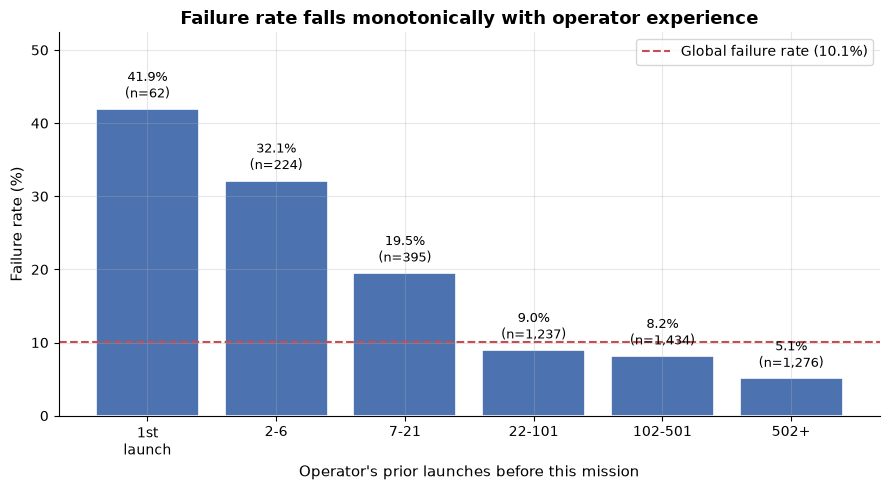

A first launch fails at 41.9%, versus 5.1% after 500+ launches.
That is a 8.2x difference.


In [36]:
# =====================================================================
# E.9 - CHART 1: the experience signal
# =====================================================================
# The headline result: failure rate falls monotonically with experience.

bins = pd.cut(
    df_eng["Company_Prior_Launches"],
    bins=[-1, 0, 5, 20, 100, 500, 100000],
    labels=["1st\nlaunch", "2-6", "7-21", "22-101", "102-501", "502+"],
)
signal = df_eng.groupby(bins, observed=True)["_is_fail"].agg(["count", "mean"])
signal["pct"] = signal["mean"] * 100

fig, ax = plt.subplots()
bars = ax.bar(signal.index.astype(str), signal["pct"],
              color="#4C72B0", edgecolor="white", linewidth=1.2)

for bar, pct, n in zip(bars, signal["pct"], signal["count"]):
    ax.text(bar.get_x() + bar.get_width() / 2, pct + 1.0,
            f"{pct:.1f}%\n(n={n:,})", ha="center", va="bottom", fontsize=9)

global_rate = df_eng["_is_fail"].mean() * 100
ax.axhline(global_rate, ls="--", color="#C44E52", linewidth=1.5,
           label=f"Global failure rate ({global_rate:.1f}%)")

ax.set_xlabel("Operator's prior launches before this mission", fontsize=11)
ax.set_ylabel("Failure rate (%)", fontsize=11)
ax.set_title("Failure rate falls monotonically with operator experience",
             fontsize=13, fontweight="bold")
ax.set_ylim(0, signal["pct"].max() * 1.25)
ax.legend()
plt.tight_layout()
plt.show()

print(f"A first launch fails at {signal['pct'].iloc[0]:.1f}%, versus "
      f"{signal['pct'].iloc[-1]:.1f}% after 500+ launches.")
print(f"That is a {signal['pct'].iloc[0] / signal['pct'].iloc[-1]:.1f}x difference.")

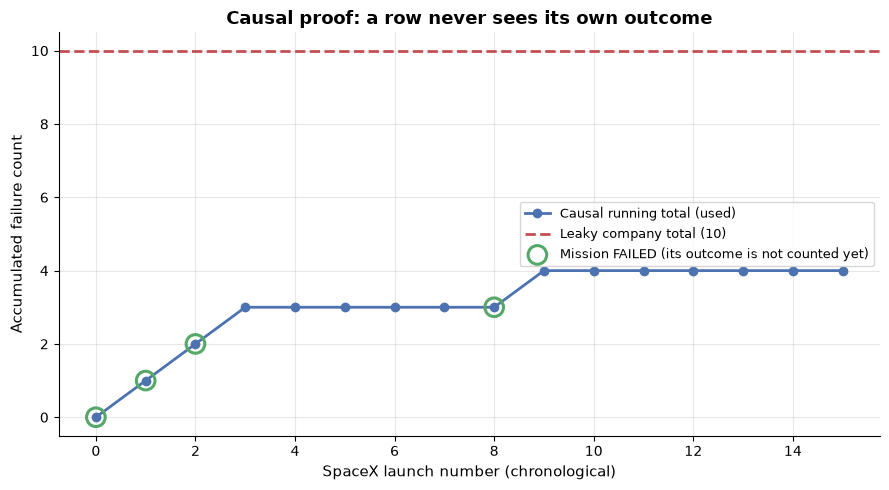

Read the first marker: SpaceX's 1st launch FAILED, yet the blue line
starts at 0 — the count does not yet include that failure. Only the
NEXT mission sees it. This is what makes the feature production-safe.


In [37]:
# =====================================================================
# E.10 - CHART 2: the causal proof
# =====================================================================
# Shows WHY the feature is safe: the running count never includes the
# current row's outcome, unlike the leaky company total.

trace = df_eng[df_eng["Company"] == "SpaceX"].sort_values("Date").head(16).reset_index(drop=True)
leaky_total = int(df.groupby("Company")["_is_fail"].sum().loc["SpaceX"])

fig, ax = plt.subplots()
x = np.arange(len(trace))

ax.plot(x, trace["Company_Prior_Failures"], "o-", color="#4C72B0",
        linewidth=2, markersize=6, label="Causal running total (used)")
ax.axhline(leaky_total, ls="--", color="#C44E52", linewidth=2,
           label=f"Leaky company total ({leaky_total})")

# Mark which missions actually failed, to show the count does NOT include them.
fail_idx = trace.index[trace["_is_fail"] == 1]
ax.scatter(fail_idx, trace.loc[fail_idx, "Company_Prior_Failures"],
           s=180, facecolors="none", edgecolors="#55A868", linewidths=2.2,
           zorder=5, label="Mission FAILED (its outcome is not counted yet)")

ax.set_xlabel("SpaceX launch number (chronological)", fontsize=11)
ax.set_ylabel("Accumulated failure count", fontsize=11)
ax.set_title("Causal proof: a row never sees its own outcome",
             fontsize=13, fontweight="bold")
ax.legend(loc="center right", fontsize=9)
plt.tight_layout()
plt.show()

print("Read the first marker: SpaceX's 1st launch FAILED, yet the blue line")
print("starts at 0 — the count does not yet include that failure. Only the")
print("NEXT mission sees it. This is what makes the feature production-safe.")

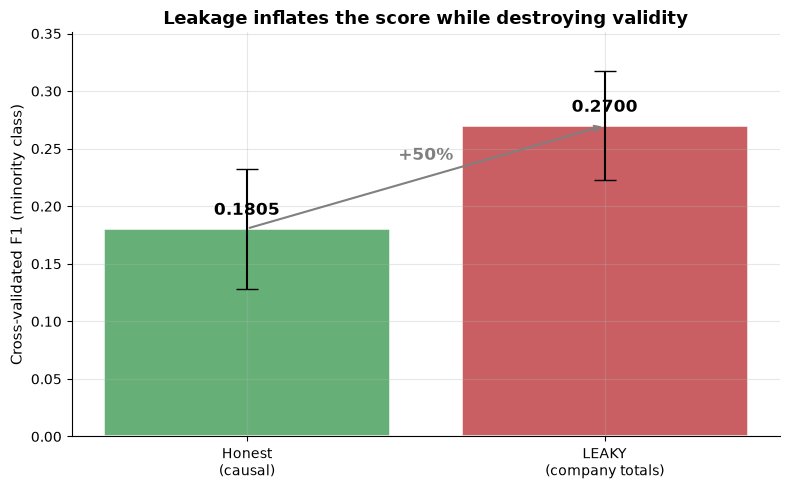

The leaky model looks 50% better and is worthless — at liftoff
nobody knows how the mission ends, so the feature could never be computed.


In [38]:
# =====================================================================
# E.11 - CHART 3: honest vs leaky performance
# =====================================================================
# Visualises why leakage is dangerous: it looks like an improvement.

fig, ax = plt.subplots(figsize=(8, 5))
labels = ["Honest\n(causal)", "LEAKY\n(company totals)"]
values = [honest_f1, leak_f1]
errors = [honest_sd, leak_sd]
colors = ["#55A868", "#C44E52"]

bars = ax.bar(labels, values, yerr=errors, capsize=8,
              color=colors, edgecolor="white", linewidth=1.2, alpha=0.9)

for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.012,
            f"{v:.4f}", ha="center", fontsize=12, fontweight="bold")

ax.set_ylabel("Cross-validated F1 (minority class)", fontsize=11)
ax.set_title("Leakage inflates the score while destroying validity",
             fontsize=13, fontweight="bold")
ax.set_ylim(0, max(values) * 1.3)
ax.annotate("", xy=(1, leak_f1), xytext=(0, honest_f1),
            arrowprops=dict(arrowstyle="->", color="gray", lw=1.5))
ax.text(0.5, (honest_f1 + leak_f1) / 2 + 0.015,
        f"+{(leak_f1/honest_f1 - 1)*100:.0f}%", ha="center",
        fontsize=12, color="gray", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"The leaky model looks {(leak_f1/honest_f1 - 1)*100:.0f}% better and is worthless — at liftoff")
print("nobody knows how the mission ends, so the feature could never be computed.")

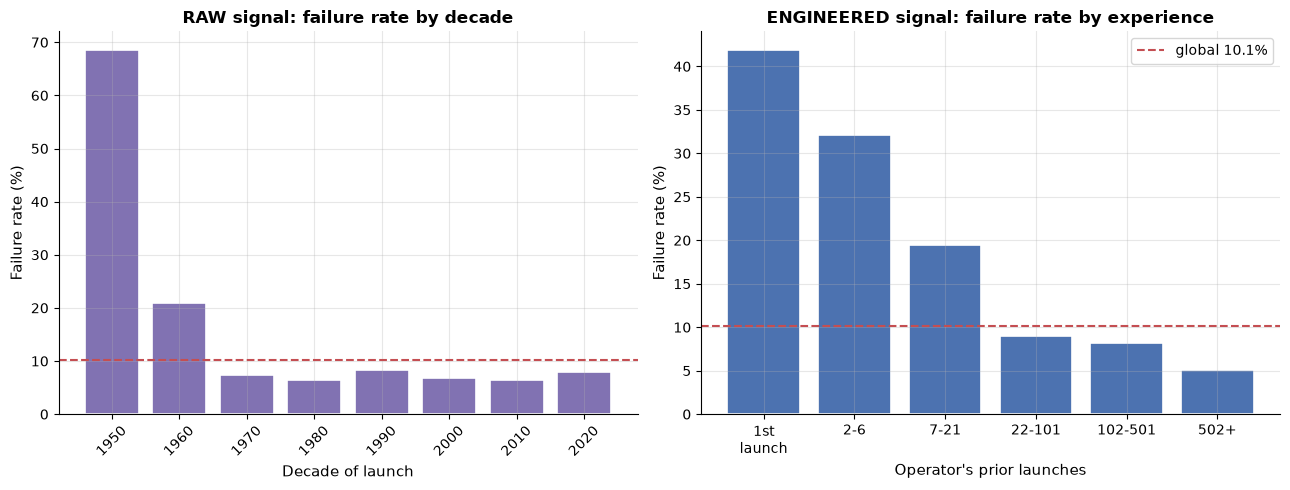

Both axes show declining risk, but they measure different things:
  LEFT  = industry-wide era effect (shared by all operators)
  RIGHT = operator-specific learning (varies by organisation)
The Part B clustering found a mid-era cluster with the LOWEST failure
rate, which is only explainable by the right-hand signal.


In [39]:
# =====================================================================
# E.12 - CHART 4: engineered vs raw, on the same axis
# =====================================================================
# Compares the engineered experience measure against the raw year signal,
# showing they capture different things.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: failure rate by era (the RAW signal)
era = df_eng.groupby(df_eng["Date"].dt.year // 10 * 10)["_is_fail"].agg(["mean", "count"])
axes[0].bar(era.index.astype(str), era["mean"] * 100, color="#8172B2",
            edgecolor="white", linewidth=1.2)
axes[0].axhline(global_rate, ls="--", color="#C44E52", linewidth=1.5)
axes[0].set_xlabel("Decade of launch", fontsize=11)
axes[0].set_ylabel("Failure rate (%)", fontsize=11)
axes[0].set_title("RAW signal: failure rate by decade", fontsize=12, fontweight="bold")
axes[0].tick_params(axis="x", rotation=45)

# Right: failure rate by experience (the ENGINEERED signal)
axes[1].bar(signal.index.astype(str), signal["pct"], color="#4C72B0",
            edgecolor="white", linewidth=1.2)
axes[1].axhline(global_rate, ls="--", color="#C44E52", linewidth=1.5,
                label=f"global {global_rate:.1f}%")
axes[1].set_xlabel("Operator's prior launches", fontsize=11)
axes[1].set_ylabel("Failure rate (%)", fontsize=11)
axes[1].set_title("ENGINEERED signal: failure rate by experience",
                  fontsize=12, fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Both axes show declining risk, but they measure different things:")
print("  LEFT  = industry-wide era effect (shared by all operators)")
print("  RIGHT = operator-specific learning (varies by organisation)")
print("The Part B clustering found a mid-era cluster with the LOWEST failure")
print("rate, which is only explainable by the right-hand signal.")

In [40]:
# =====================================================================
# E.13 - Part E summary
# =====================================================================

summary_e = pd.DataFrame([
    {"feature": "Company_Prior_Launches", "kept": "Yes",
     "why": "Primary experience measure; monotonic 41.9% -> 5.1% signal."},
    {"feature": "Company_Prior_Failure_Rate", "kept": "Yes",
     "why": "Adds the quality dimension (50 launches with 10 failures != 50 with 0)."},
    {"feature": "Company_Prior_Failures", "kept": "No",
     "why": "0.952 correlation with prior launches - near-redundant."},
    {"feature": "Is_First_Company_Launch", "kept": "No",
     "why": "Derivable from prior_launches == 0."},
]).set_index("feature")

display(summary_e)
print(f"Final engineered features: {list(experience_builder.feature_names)}")
print(f"Dataframe shape           : {df_eng.shape}")

,kept,why
feature,,
Company_Prior_Launches,Yes,Primary experience measure; monotonic 41.9% ->...
Company_Prior_Failure_Rate,Yes,Adds the quality dimension (50 launches with 1...
Company_Prior_Failures,No,0.952 correlation with prior launches - near-r...
Is_First_Company_Launch,No,Derivable from prior_launches == 0.


Final engineered features: ['Company_Prior_Launches', 'Company_Prior_Failure_Rate']
Dataframe shape           : (4628, 16)
